# Continual learning metrics: model comparison

Compares class-incremental split-MNIST models using the files written by `get_cl_metrics.py` (run it once per model first):

```bash
# from the EIANN/ package directory
python scripts/get_cl_metrics.py --model-folder-path=data/<network_name> --data-dir=data/datasets/MNIST_data/ \
    --num-splits=5 --label=<model key> --model-key=<model key>
```

| File in `data/cl_metrics/` | Used in |
|---|---|
| `<model_key>_accuracy.csv` | cumulative accuracy, CL summary, accuracy matrices |
| `<model_key>_fisher.h5` | Fisher information vs weight change; weights for the utility plot |
| `<model_key>_activity.h5` | population activity, weight change vs contribution utility |

Tasks are numbered from 1 in plots (task 1 = digits 0-1 for 5 splits). Phase *i* in the files is the network after training on task *i*+1.

In [1]:
import os, glob, re
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.patheffects as patheffects
import h5py
from scipy.stats import spearmanr, pearsonr
from scipy.ndimage import gaussian_filter1d

import EIANN.utils as ut

%load_ext autoreload
%autoreload 2

## Setup
`models` maps each model key (the `--model-key` given to `get_cl_metrics.py`) to a display label and color. Set it to `None` to use every model found in `metrics_dir`.

In [2]:
metrics_dir = '../data/cl_metrics'
plot_dir = '../data/cl_plots'  # gitignored
os.makedirs(plot_dir, exist_ok=True)

models = {
    # one unique color per model (validated for adjacent-pair color-vision-deficiency separation); keep in sync across cells
    'van_bp_CL_5_tasks_G':        {'label': 'Backprop',                    'color': '#2a78d6'},  # blue
    'van_bp_CL_5_tasks_EWC':      {'label': 'Backprop + EWC',              'color': '#e34948'},  # red
    'van_bp_CL_5_tasks_EWC_LR':   {'label': 'Backprop + EWC ELR',          'color': '#eda100'},  # yellow
    'van_bp_CL_5_tasks_SI':       {'label': 'Backprop + SI',               'color': '#008300'},  # green
    'van_bp_CL_5_tasks_SI_LR':    {'label': 'Backprop + SI ELR',           'color': '#e87ba4'},  # pink
    'van_bp_CL_5_tasks_SI_HG_v1': {'label': 'Backprop + SI HG',            'color': '#00807f'},  # teal
    'bpDale_CL_5_tasks_G':        {'label': "Backprop (Dale's Law)",       'color': '#4a3aa7'},  # violet
    'bpDale_CL_5_tasks_SI':       {'label': "Backprop (Dale's Law) + SI",  'color': '#1baf7a'},  # aqua
    'bpDale_CL_5_tasks_EWC':      {'label': "Backprop (Dale's Law) + EWC", 'color': '#b5179e'},  # plum
    'BP_like_CL_5_tasks_5J':      {'label': 'DTP',                         'color': '#1a1a1a'},  # black
    'dtp_CL_5_tasks_SI':          {'label': 'DTP + SI',                    'color': '#eb6834'},  # orange
    'BTSP_CL_5_tasks_6L':         {'label': 'BTSP',                        'color': '#8c564b'},  # brown
    'BTSP_CL_5_tasks_ELR_A':      {'label': 'BTSP + ELR',                  'color': '#56b4e9'},  # sky blue
    'BTSP_SI_CL_5_tasks':         {'label': 'BTSP + SI',                   'color': '#9a9a00'},  # olive
    'BTSP_BP_CL_5_tasks':         {'label': 'BTSP (BP plateaus)',          'color': '#9467bd'},  # purple
}

if models is None:
    keys = sorted(os.path.basename(f)[:-len('_accuracy.csv')] for f in glob.glob(f'{metrics_dir}/*_accuracy.csv'))
    colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
    models = {key: {'label': key, 'color': colors[i % len(colors)]} for i, key in enumerate(keys)}

missing = [model for model in models if not os.path.exists(f'{metrics_dir}/{model}_accuracy.csv')]
if missing:
    print(f'skipping models without get_cl_metrics.py outputs in {metrics_dir}: {missing}')
models = {model: style for model, style in models.items() if model not in missing}

In [3]:
# keep text as real text objects so labels stay editable in Illustrator
mpl.rcParams['svg.fonttype'] = 'none'
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.sans-serif'] = ['Helvetica', 'Arial', 'DejaVu Sans']

INK = '#1a1a1a'
MUTED = '#6b6b6b'
FONT_SIZE = 16  # axis labels and titles; tick labels, legends and in-plot text are scaled down from it

mpl.rcParams.update({
    'font.size': FONT_SIZE,
    'axes.labelsize': 'medium', 'axes.titlesize': 'medium', 'figure.titlesize': 'medium',
    'xtick.labelsize': 'small', 'ytick.labelsize': 'small', 'legend.fontsize': 'small',
    'text.color': INK, 'axes.labelcolor': INK, 'axes.edgecolor': INK, 'xtick.color': INK, 'ytick.color': INK,
    'axes.linewidth': 1.0,
    'image.interpolation': 'none',  # heatmap cells stay crisp instead of being resampled
    'savefig.dpi': 300,
})


def _svg_font_longhand(match):
    """
    Rewrite matplotlib's CSS shorthand `font: [italic] [bold] 12px 'Helvetica', ...` as separate properties.
    """
    *modifiers, size = match.group(1).split()
    style = [f'font-style: {m}' if m in ('italic', 'oblique') else f'font-weight: {m}' for m in modifiers]
    return '; '.join(style + [f'font-size: {size}', f'font-family: {match.group(2)}'])


def save_fig(fig, name):
    """
    Save fig to plot_dir as <name>.svg (editable text, transparent background).
    Some editors (e.g. Illustrator) ignore the `font:` shorthand matplotlib writes and fall back to a default size,
    so font size and family are written as separate properties.
    """
    path = f'{plot_dir}/{name}.svg'
    fig.savefig(path, format='svg', transparent=True, bbox_inches='tight')
    with open(path) as f:
        svg = f.read()
    with open(path, 'w') as f:
        f.write(re.sub(r'font: ((?:[\w-]+ )*[\d.]+px) ([^;"]+)', _svg_font_longhand, svg))


def style_axes(ax):
    for side in ('top', 'right'):
        ax.spines[side].set_visible(False)
    ax.tick_params(axis='both', which='both', length=6, width=1.0, color=INK, labelcolor=INK)
    ax.xaxis.label.set_color(INK)
    ax.yaxis.label.set_color(INK)

## Accuracy
`<model_key>_accuracy.csv` has one row per (seed, phase, test set). `test_set` is `task<j>` (test set of task *j*), `seen` (mean over the tasks learned so far) or `all` (full 10-class test set).

In [4]:
acc_df = pd.concat([pd.read_csv(f'{metrics_dir}/{model}_accuracy.csv', dtype={'seed': str}) for model in models],
                   ignore_index=True)
num_tasks = acc_df.phase.nunique()
classes_per_task = 10 // num_tasks


def accuracy_matrices(df):
    """
    :return: dict {model: array (seeds, phases, tasks)}; entry [s, i, j] is the accuracy on task j after training on task i
    """
    tasks = df[df.test_set.str.startswith('task')].assign(task=lambda d: d.test_set.str[4:].astype(int))
    matrices = {}
    for model, model_df in tasks.groupby('model', sort=False):
        table = model_df.pivot_table(index=['seed', 'phase'], columns='task', values='accuracy')
        num_seeds = table.index.get_level_values('seed').nunique()
        matrices[model] = table.values.reshape(num_seeds, -1, table.shape[1])
    return matrices


acc_matrices = accuracy_matrices(acc_df)
acc_df.groupby('model', sort=False).seed.nunique().rename('num_seeds').to_frame()

,num_seeds
model,
van_bp_CL_5_tasks_G,5
van_bp_CL_5_tasks_EWC,5
van_bp_CL_5_tasks_EWC_LR,5
van_bp_CL_5_tasks_SI,5
van_bp_CL_5_tasks_SI_LR,5
van_bp_CL_5_tasks_SI_HG_v1,5
bpDale_CL_5_tasks_G,5
bpDale_CL_5_tasks_SI,5
bpDale_CL_5_tasks_EWC,5


### Cumulative accuracy
Mean accuracy over the tasks learned so far (`seen`), mean ± std across seeds. The dashed line is complete forgetting: only the latest task is classified correctly.

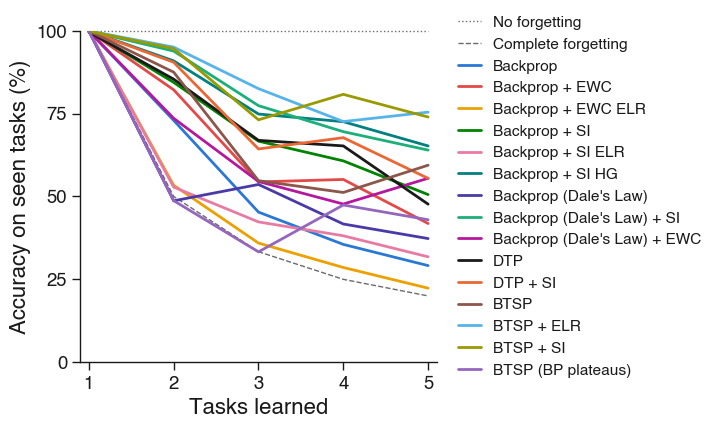

phase,task 1,task 2,task 3,task 4,task 5
model,,,,,
van_bp_CL_5_tasks_G,99.8,72.9,45.3,35.5,29.1
van_bp_CL_5_tasks_EWC,99.9,82.2,54.4,55.1,41.8
van_bp_CL_5_tasks_EWC_LR,99.8,53.4,35.9,28.6,22.3
van_bp_CL_5_tasks_SI,99.9,84.4,66.7,60.7,50.6
van_bp_CL_5_tasks_SI_LR,99.9,52.8,42.3,38.1,31.8
van_bp_CL_5_tasks_SI_HG_v1,99.9,90.9,74.8,72.5,65.2
bpDale_CL_5_tasks_G,99.9,48.7,53.6,41.7,37.3
bpDale_CL_5_tasks_SI,99.9,93.8,77.4,69.5,64.0
bpDale_CL_5_tasks_EWC,99.9,73.6,54.5,47.7,55.5


In [5]:
seen = acc_df[acc_df.test_set == 'seen'].groupby(['model', 'phase']).accuracy.agg(['mean', 'std'])


def plot_cumulative_accuracy(model_keys, name, show_std=True):
    """
    Mean (± std across seeds) accuracy on seen tasks after each task, one line per model, saved as <name>.svg.
    :param model_keys: list of keys of models, in legend order
    :param show_std: shade ± std across seeds
    """
    x = np.arange(1, num_tasks + 1)
    fig, ax = plt.subplots(figsize=(7.5, 4.5))  # extra width for the legend; short so the legend spans more of the height
    ax.plot(x, np.full(len(x), 100), color=MUTED, linestyle=':', linewidth=1.0, clip_on=False, label='No forgetting')
    ax.plot(x, 100 / x, color=MUTED, linestyle='--', linewidth=1.0, label='Complete forgetting')
    for model in model_keys:
        style = models[model]
        mean, std = seen.loc[model, 'mean'].values, seen.loc[model, 'std'].values
        ax.plot(x, mean, color=style['color'], linewidth=2.0, solid_capstyle='round', label=style['label'])
        if show_std:
            ax.fill_between(x, mean - std, mean + std, color=style['color'], alpha=0.25, linewidth=0)

    ax.set_xlim(0.9, num_tasks + 0.1)
    ax.set_ylim(0, 100)
    ax.set_xticks(x)
    ax.set_yticks([0, 25, 50, 75, 100])
    ax.set_xlabel('Tasks learned')
    ax.set_ylabel('Accuracy on seen tasks (%)')
    # outside the axes so it never covers the curves
    ax.legend(frameon=False, loc='center left', bbox_to_anchor=(1.02, 0.5), fontsize='x-small', handlelength=1.5)
    style_axes(ax)
    fig.tight_layout()
    save_fig(fig, name)
    plt.show()


plot_cumulative_accuracy(list(models), 'cumulative_accuracy', show_std=False)
seen['mean'].unstack('phase').loc[list(models)].rename(columns=lambda p: f'task {p + 1}').round(1)


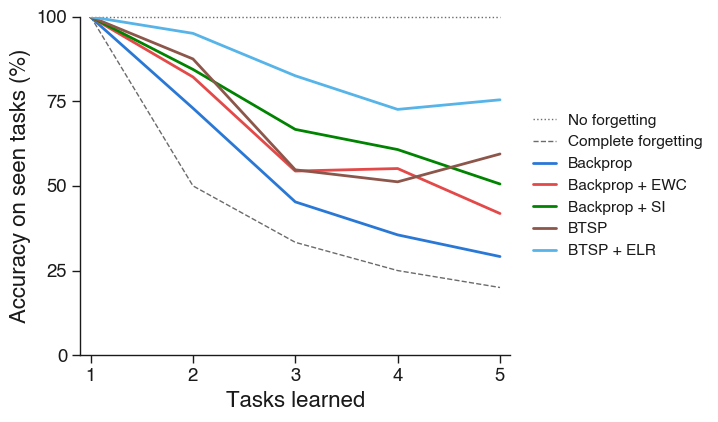

In [6]:
# a subset of models, in legend order (keys of `models`)
subset_models = ['van_bp_CL_5_tasks_G', 'van_bp_CL_5_tasks_EWC', 'van_bp_CL_5_tasks_SI', 'BTSP_CL_5_tasks_6L', 'BTSP_CL_5_tasks_ELR_A']
plot_cumulative_accuracy(subset_models, 'cumulative_accuracy_subset', show_std=False)


### CL summary
Per seed, from the accuracy matrix $A_{ij}$ (accuracy on task *j* after training on task *i*), as in Díaz-Rodríguez et al. 2018 (arXiv:1810.13166):
- **on-task**: mean of $A_{ii}$, accuracy on each task right after learning it
- **ACC**: mean of $A_{ij}$ for $i \geq j$
- **BWT**: mean of $A_{ij} - A_{jj}$ for $i > j$ (negative = forgetting)
- **FWT**: mean of $A_{ij}$ for $i < j$ (≈ 0 in class-incremental runs, since unseen classes are never predicted)
- **final seen** / **final all**: accuracy after the last task on the seen tasks / the full test set

In [7]:
def cl_metrics(A):
    """
    :param A: array (phases, tasks)
    :return: dict
    """
    T = A.shape[0]
    return {'on-task': np.mean(np.diag(A)),
            'ACC': A[np.tril_indices(T)].mean(),
            'BWT': np.mean([A[i, j] - A[j, j] for i in range(T) for j in range(i)]),
            'FWT': A[np.triu_indices(T, k=1)].mean(),
            'final seen': A[-1].mean()}


final_all = acc_df[(acc_df.test_set == 'all') & (acc_df.phase == num_tasks - 1)].groupby('model').accuracy
summary_rows = []
for model, matrices in acc_matrices.items():
    for A in matrices:
        summary_rows.append({'model': model, **cl_metrics(A)})
summary = pd.DataFrame(summary_rows).groupby('model', sort=False).agg(['mean', 'std'])
summary[('final all', 'mean')] = final_all.mean()
summary[('final all', 'std')] = final_all.std()
summary.rename(index={model: style['label'] for model, style in models.items()}).round(2)

on-task           ACC          BWT          FWT  \
                               mean    std   mean   std   mean    std  mean   
model                                                                         
Backprop                      86.49  11.42  44.62  0.92 -68.34  10.69  0.05   
Backprop + EWC                82.56   5.04  57.13  1.69 -46.78   4.49  0.00   
Backprop + EWC ELR            75.45  14.69  36.03  1.79 -72.90  12.91  0.15   
Backprop + SI                 71.31  13.97  64.29  8.25 -26.25   8.36  0.01   
Backprop + SI ELR             31.73   6.01  42.93  4.31   0.31   0.79  0.53   
Backprop + SI HG              86.04   2.19  74.83  2.55 -22.62   5.53  0.00   
Backprop (Dale's Law)         47.39  17.81  47.42  3.72 -27.66  27.72  0.00   
Backprop (Dale's Law) + SI    80.47   6.45  74.51  1.69 -23.07   2.61  0.00   
Backprop (Dale's Law) + EWC   77.42   6.92  58.58  2.73 -46.43   8.64  0.00   
DTP                           88.66   2.80  64.69  2.73 -37.38   6.87  0.00   
DTP + SI                      88.27   2.91  68.13  2.88 -34.38   6.70  0.00   
BTSP                          76.44   4.51  62.73  2.54 -41.39   1.89  0.00   
BTSP + ELR                    90.74   0.66  80.32  0.59 -19.32   0.97  0.19   
BTSP + SI                     90.35   2.25  80.08  1.19 -21.15   1.36  0.00   
BTSP (BP plateaus)            59.28   0.07  46.78  0.64 -48.46   1.00  0.00   

                                  final seen       final all        
                              std       mean   std      mean   std  
model                                                               
Backprop                     0.05      29.14  4.41     29.24  4.52  
Backprop + EWC               0.00      41.84  6.59     41.84  6.63  
Backprop + EWC ELR           0.11      22.34  3.18     22.44  3.40  
Backprop + SI                0.01      50.55  8.95     50.99  8.81  
Backprop + SI ELR            0.83      31.79  5.44     32.75  5.46  
Backprop + SI HG             0.00      65.22  1.44     65.35  1.57  
Backprop (Dale's Law)        0.00      37.30  3.28     38.36  2.62  
Backprop (Dale's Law) + SI   0.00      63.97  3.25     64.42  3.01  
Backprop (Dale's Law) + EWC  0.00      55.48  6.33     55.79  6.15  
DTP                          0.00      47.67  3.73     47.92  3.69  
DTP + SI                     0.00      55.45  7.37     55.97  7.36  
BTSP                         0.00      59.42  3.98     59.82  3.91  
BTSP + ELR                   0.30      75.41  1.89     75.94  1.79  
BTSP + SI                    0.00      73.94  2.29     74.32  2.15  
BTSP (BP plateaus)           0.00      42.96  1.49     42.86  1.56

### Accuracy matrices
Mean across seeds. Row *i*: after training on task *i*; column *j*: test set of task *j*.

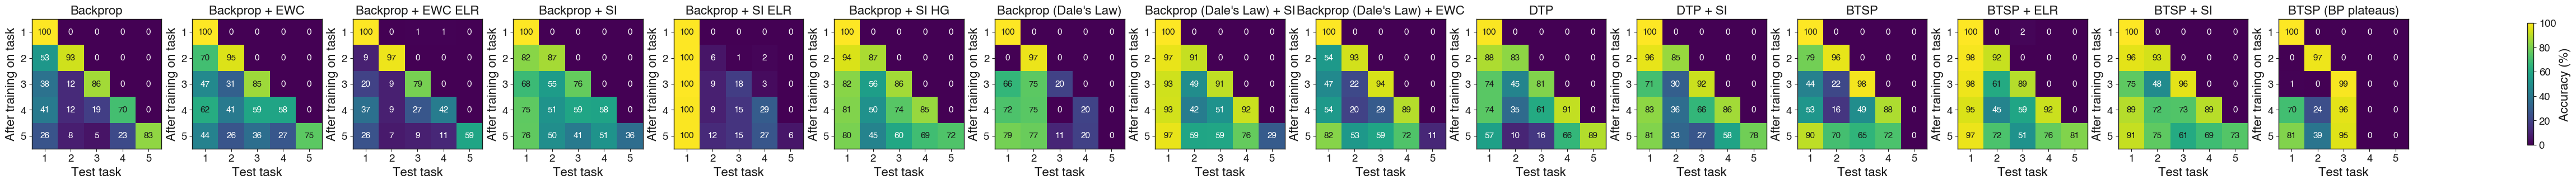

In [8]:
fig, axes = plt.subplots(1, len(models), figsize=(3.0 * len(models) + 1, 3.2), squeeze=False, layout='constrained')
ticks = np.arange(num_tasks)
for ax, (model, style) in zip(axes[0], models.items()):
    A = acc_matrices[model].mean(0)
    im = ax.imshow(A, vmin=0, vmax=100, cmap='viridis')
    for i in range(num_tasks):
        for j in range(num_tasks):
            ax.text(j, i, f'{A[i, j]:.0f}', ha='center', va='center', fontsize='x-small',
                    color='white' if A[i, j] < 60 else INK)
    ax.set_xticks(ticks, ticks + 1)
    ax.set_yticks(ticks, ticks + 1)
    ax.set_xlabel('Test task')
    ax.set_ylabel('After training on task')
    ax.set_title(style['label'])
fig.colorbar(im, ax=axes[0].tolist(), shrink=0.8, label='Accuracy (%)')
save_fig(fig, 'accuracy_matrices')
plt.show()

### Per-task accuracy over training
Accuracy on each task from the phase it was learned onward, for one model. Δ is the change from right after learning the task to the end.

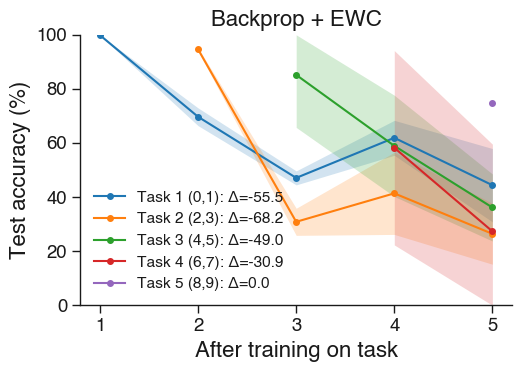

In [9]:
model = 'van_bp_CL_5_tasks_EWC'

A = acc_matrices[model]
mean, std = A.mean(0), A.std(0)
fig, ax = plt.subplots(figsize=(5.5, 4.0))
for j in range(num_tasks):
    t = np.arange(j, num_tasks)
    classes = ','.join(str(c) for c in range(j * classes_per_task, (j + 1) * classes_per_task))
    line, = ax.plot(t + 1, mean[j:, j], marker='o', markersize=4,
                    label=f'Task {j + 1} ({classes}): Δ={mean[-1, j] - mean[j, j]:.1f}')
    ax.fill_between(t + 1, np.clip(mean[j:, j] - std[j:, j], 0, 100), np.clip(mean[j:, j] + std[j:, j], 0, 100),
                    color=line.get_color(), alpha=0.2, linewidth=0)
ax.set_xticks(np.arange(1, num_tasks + 1))
ax.set_ylim(0, 100)
ax.set_xlabel('After training on task')
ax.set_ylabel('Test accuracy (%)')
ax.set_title(models[model]['label'])
ax.legend(frameon=False, fontsize='x-small', loc='lower left')
style_axes(ax)
fig.tight_layout()
save_fig(fig, f'{model}_task_accuracy')
plt.show()

## Fisher information vs weight change
`<model_key>_fisher.h5` holds, after each phase *i*, the weights `<seed>/phase<i>/weight/<proj>` and their diagonal empirical Fisher, both shaped (post, pre): `fisher` on the task just learned and `cumulative_fisher` on all tasks learned so far (equal weight per task). Projection names are `<post>_<pre>`.

Each panel compares, per weight, the cumulative Fisher after task *i* with the weight change during the next task, |ΔW| = |W after task *i*+1 − W after task *i*|, on log–log axes (color: number of weights, log scale). If a rule protects the weights that matter for the tasks learned so far, high-Fisher weights should change less. Column *k*: Fisher after task *k*−1, ΔW during task *k*. float32 resolves a weight change only to about |W| × 6e-8, and weights stuck near 0 (Dale's-law bounds, multiplicative decay) can still differ by as little as 1e-40. So |ΔW| below `dw_lower_bound` counts as no change, and *silent* weights, with |W| below `silent_weight_bound` both before and after the task, are left out (% silent in each panel). With `quantity='lr_mod'` the y axis is instead the learning rate modulation `lr_mod` after each task (`<seed>/phase<i>/lr_mod/<proj>`, saved for rules with one, e.g. the elastic learning rate of BTSP + ELR), against the Fisher at the same phase, one column per task (silent weights: |W| < `silent_weight_bound` after that task). This tests whether the rule lowers the learning rate of weights that matter for the tasks learned so far. With `relative=True` the y axis is the relative change |ΔW| / |W after task *i*| (denominator floored at `silent_weight_bound`; `dw_lower_bound` still applies to |ΔW|), which removes the dependence on weight scale. Weights with F = 0 or no change can't be shown on log axes either (*n* = % of weights shown), and ρ is the Spearman correlation of the rest. `log_scale=False` plots both axes on a linear scale instead, keeping zeros, with the Pearson r in place of ρ. `log_scale='fisher'` keeps only the Fisher axis on a log scale (semi-log), keeping weights with no change but leaving out F = 0, with ρ (the same for log or linear y, since it uses ranks). The same option applies to the `lr_mod` plot below. With `fisher_key='rule_importance'` the x axis is instead the CL rule's own importance in effect during task *i*+1 (`<seed>/phase<i>/rule_importance/<proj>`: the summed Fisher ΣF for EWC and EWC_LR, ω for SI and SI_LR), so it tests whether the rule moves less the weights that it itself treats as important. It is computed at the task switch, so there is none after the last task. Raw correlations are inflated by activity: F and |ΔW| are both large for weights from active inputs onto units with large errors, so compare ρ with plain backprop rather than with 0.

In [10]:
def fisher_path(model):
    return f'{metrics_dir}/{model}_fisher.h5'


def fisher_seeds(model):
    with h5py.File(fisher_path(model), 'r') as f:
        return sorted(f.keys())


def load_fisher(model, seed):
    """
    :return: dict {'learning_rule': {proj: bytes}, 'phase<i>': {'fisher' | 'cumulative_fisher' | 'weight' | ...: {proj: (post, pre)}}}
    """
    return ut.hdf5_to_dict(fisher_path(model), variable_name=seed)


def abs_weight_change(fi, projection, phase, dw_lower_bound, silent_weight_bound, relative=False):
    """
    :param dw_lower_bound: float; |ΔW| below this is set to 0 (no change)
    :param silent_weight_bound: float; weights with |W| below this before and after the task are silent
    :param relative: if True, return |ΔW| / |W before the task|, with the denominator floored at silent_weight_bound
    :return: tuple of arrays (post, pre): |ΔW| (or relative change) during the task after phase; bool, True for silent
        weights
    """
    W_before, W_after = fi[f'phase{phase}']['weight'][projection], fi[f'phase{phase + 1}']['weight'][projection]
    dW = np.abs(W_after - W_before)
    dW[dW < dw_lower_bound] = 0
    if relative:
        dW = dW / np.maximum(np.abs(W_before), silent_weight_bound)
    silent = np.maximum(np.abs(W_before), np.abs(W_after)) < silent_weight_bound
    return dW, silent


def weight_quantity(fi, projection, phase, quantity, dw_lower_bound, silent_weight_bound, relative=False):
    """
    :param quantity: 'dW' (|ΔW| during the task after phase, as in abs_weight_change) or 'lr_mod' (learning rate
        modulation after phase, in effect during the next task; silent weights: |W| below silent_weight_bound after
        phase)
    :return: tuple of arrays (post, pre): values; bool, True for silent weights
    """
    if quantity == 'lr_mod':
        W = fi[f'phase{phase}']['weight'][projection]
        return fi[f'phase{phase}']['lr_mod'][projection], np.abs(W) < silent_weight_bound
    return abs_weight_change(fi, projection, phase, dw_lower_bound, silent_weight_bound, relative)


def plot_phases(quantity):
    """
    :return: tuple (phases, column titles): weight changes are plotted during each task after the first; lr_mod at
        the same phase as the Fisher or utility, after every task
    """
    if quantity == 'lr_mod':
        return range(num_tasks), [f'After task {phase + 1}' for phase in range(num_tasks)]
    return range(num_tasks - 1), [f'During task {phase + 2}' for phase in range(num_tasks - 1)]


def weight_change_label(relative, quantity='dW'):
    if quantity == 'lr_mod':
        return 'lr_mod'
    return '|ΔW| / |W|' if relative else '|ΔW|'


def weight_quantity_file_label(relative, quantity='dW'):
    if quantity == 'lr_mod':
        return 'lr_mod'
    return 'rel_dw' if relative else 'dw'


def importance_label(fi, fisher_key):
    """
    :return: str; x axis label for fisher_key
    """
    if fisher_key == 'rule_importance':
        rules = {rule.decode() for rule in fi['learning_rule'].values()}
        return 'Rule importance (ω)' if any('_SI' in rule for rule in rules) else 'Rule importance (ΣF)'
    return 'Cumulative Fisher' if fisher_key == 'cumulative_fisher' else 'Fisher (last task)'


def axis_scales(log_scale):
    """
    :param log_scale: True (log-log), 'fisher' (semi-log: log Fisher on the x axis, linear y axis) or False (linear)
    :return: tuple of str: x axis scale, y axis scale
    """
    if log_scale == 'fisher':
        return 'log', 'linear'
    return ('log', 'log') if log_scale else ('linear', 'linear')


def scale_file_label(log_scale):
    if log_scale == 'fisher':
        return '_semilog'
    return '' if log_scale else '_linear'


def annotate_correlation(ax, x, y, total, num_silent=0, log_scale=True, show_counts=True, text_y=None):
    """
    Spearman ρ on log and semi-log axes (log_scale True or 'fisher'), Pearson r on linear axes, with the % of points
    shown (n) and of silent weights if show_counts.
    :param text_y: float; y (data units) just above which the text sits; None: top left corner of the axes
    """
    if log_scale:
        label, corr = 'ρ', spearmanr(x, y)[0] if len(x) > 2 else np.nan
    else:
        label, corr = 'r', pearsonr(x, y)[0] if len(x) > 2 else np.nan
    text = f'{label} = {corr:.2f}'
    if show_counts:
        text += f', n = {100 * len(x) / total:.0f}%'
    if show_counts and num_silent:
        text += f', silent {100 * num_silent / total:.0f}%'
    if text_y is None:
        position, transform, va = (0.03, 0.97), ax.transAxes, 'top'
    else:
        # x in axes units, y in data units, raised 3 points so the text clears the data at text_y
        position, va = (0.03, text_y), 'bottom'
        transform = mpl.transforms.offset_copy(ax.get_yaxis_transform(), fig=ax.figure, y=3, units='points')
    ax.text(*position, text, transform=transform, ha='left', va=va, fontsize='x-small', in_layout=False,
            bbox={'facecolor': 'white', 'alpha': 0.7, 'linewidth': 0, 'pad': 1})


def plastic_projections(fi, fisher_key, lr_mod=False):
    """
    :param lr_mod: if True, keep only projections with a learning rate modulation
    :return: list of str; plastic projections with a nonzero fisher_key after the first task
    """
    return [name for name, rule in fi['learning_rule'].items()
            if rule.decode() != 'LearningRule' and name in fi['phase0'].get(fisher_key, {}) and
            fi['phase0'][fisher_key][name].any() and (not lr_mod or name in fi['phase0'].get('lr_mod', {}))]


def plot_dw_vs_fisher(model, seed=None, projections=None, fisher_key='cumulative_fisher', dw_lower_bound=1e-8,
                      silent_weight_bound=1e-6, relative=False, quantity='dW', log_scale=True):
    """
    |ΔW| during task i+1 against the Fisher after task i, per weight; rows: projections, columns: task switches. With
    quantity='lr_mod': lr_mod after task i against the Fisher after task i, one column per task.
    :param seed: str; None: first seed
    :param projections: list of str; None: every plastic projection with a nonzero Fisher (with lr_mod for
        quantity='lr_mod')
    :param fisher_key: 'cumulative_fisher' (tasks learned so far), 'fisher' (task just learned) or 'rule_importance'
        (the CL rule's own importance in effect during task i+1, for EWC/SI-type rules)
    :param dw_lower_bound: float; |ΔW| below this counts as no change
    :param silent_weight_bound: float; weights with |W| below this before and after the task are left out
    :param relative: if True, plot the relative change |ΔW| / |W before the task|
    :param quantity: 'dW' (weight change) or 'lr_mod' (learning rate modulation after task i)
    :param log_scale: True: log-log axes and Spearman ρ, leaving out zeros; 'fisher': log Fisher axis and linear y axis
        (semi-log) and Spearman ρ, leaving out F = 0; False: linear axes and Pearson r, keeping zeros
    """
    seed = fisher_seeds(model)[0] if seed is None else seed
    fi = load_fisher(model, seed)
    if projections is None:
        projections = plastic_projections(fi, fisher_key, lr_mod=quantity == 'lr_mod')
    phases, titles = plot_phases(quantity)
    # rule_importance is set at the task switch, so there is none after the last task
    phases, titles = zip(*[(phase, title) for phase, title in zip(phases, titles) if fisher_key in fi[f'phase{phase}']])
    fig, axes = plt.subplots(len(projections), len(phases), figsize=(2.8 * len(phases), 2.6 * len(projections)),
                             squeeze=False, layout='constrained')
    for row, projection in zip(axes, projections):
        for phase, ax in zip(phases, row):
            F = fi[f'phase{phase}'][fisher_key][projection].ravel()
            dW, silent = weight_quantity(fi, projection, phase, quantity, dw_lower_bound, silent_weight_bound,
                                         relative)
            dW, silent = dW.ravel(), silent.ravel()
            xscale, yscale = axis_scales(log_scale)
            keep = ~silent & ((F > 0) if xscale == 'log' else True) & ((dW > 0) if yscale == 'log' else True)
            if keep.any():
                ax.hexbin(F[keep], dW[keep], xscale=xscale, yscale=yscale, bins='log', gridsize=40, mincnt=1,
                          cmap='viridis', linewidths=0)
            annotate_correlation(ax, F[keep], dW[keep], F.size, silent.sum(), log_scale)
            style_axes(ax)
        row[0].set_ylabel(f'{projection}\n{weight_change_label(relative, quantity)}')
    for title, ax in zip(titles, axes[0]):
        ax.set_title(title)
    for ax in axes[-1]:
        ax.set_xlabel(importance_label(fi, fisher_key))
    y_title = 'Learning Rate Scaler' if quantity == 'lr_mod' else 'Weight Updates'
    x_title = 'Rule Importance' if fisher_key == 'rule_importance' else 'Fisher Information'
    fig.suptitle(f'{models[model]["label"]}: {y_title} vs. {x_title}')
    save_fig(fig, f'{model}_{weight_quantity_file_label(relative, quantity)}_vs_{fisher_key}'
                  f'{scale_file_label(log_scale)}_seed{seed}')
    plt.show()

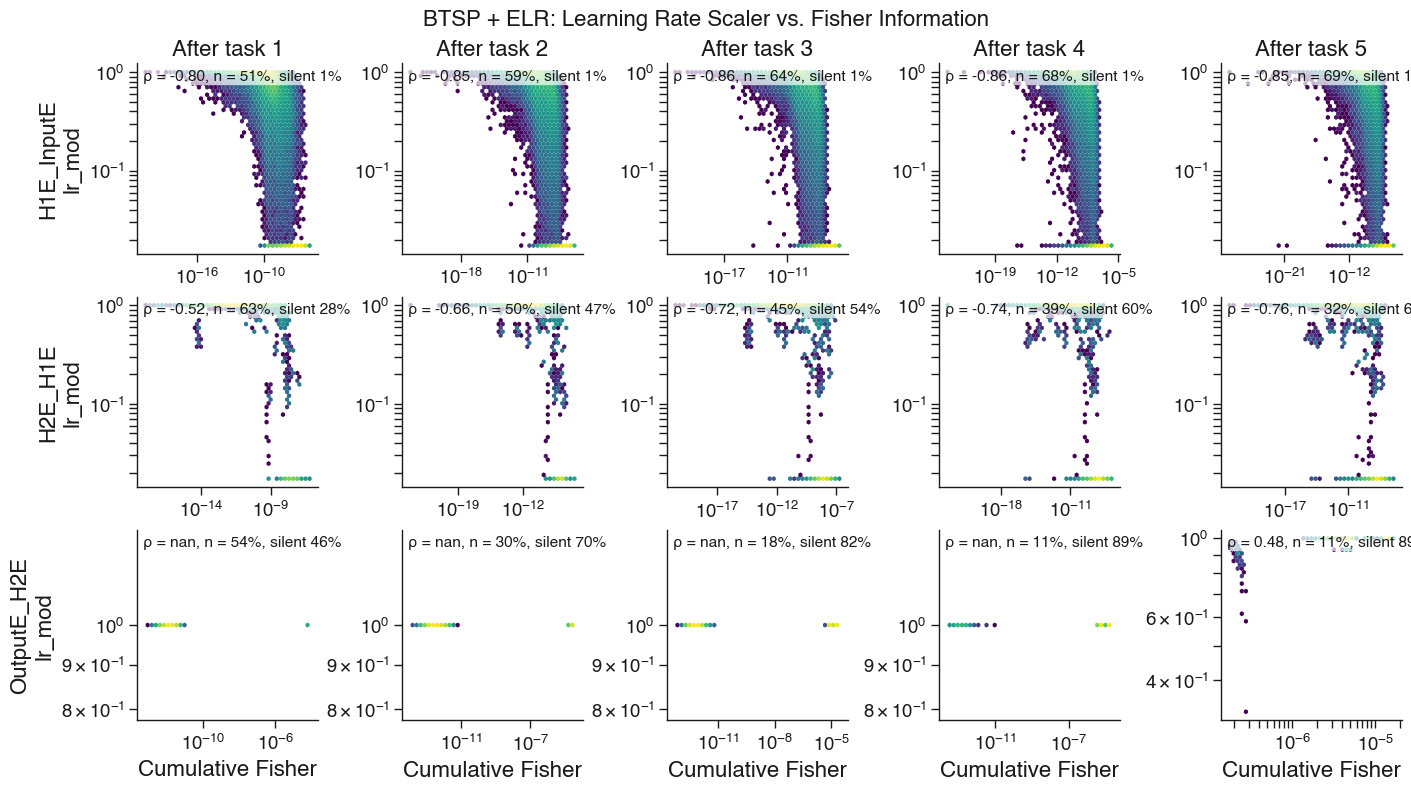

In [11]:
models = {
    # one unique color per model (validated for adjacent-pair color-vision-deficiency separation); keep in sync across cells
    'van_bp_CL_5_tasks_G':        {'label': 'Backprop',                    'color': '#2a78d6'},  # blue
    'van_bp_CL_5_tasks_EWC':      {'label': 'Backprop + EWC',              'color': '#e34948'},  # red
    'van_bp_CL_5_tasks_EWC_LR':   {'label': 'Backprop + EWC ELR',          'color': '#eda100'},  # yellow
    'van_bp_CL_5_tasks_SI':       {'label': 'Backprop + SI',               'color': '#008300'},  # green
    'van_bp_CL_5_tasks_SI_LR':    {'label': 'Backprop + SI ELR',           'color': '#e87ba4'},  # pink
    'van_bp_CL_5_tasks_SI_HG_v1': {'label': 'Backprop + SI HG',            'color': '#00807f'},  # teal
    'bpDale_CL_5_tasks_G':        {'label': "Backprop (Dale's Law)",       'color': '#4a3aa7'},  # violet
    'bpDale_CL_5_tasks_SI':       {'label': "Backprop (Dale's Law) + SI",  'color': '#1baf7a'},  # aqua
    'bpDale_CL_5_tasks_EWC':      {'label': "Backprop (Dale's Law) + EWC", 'color': '#b5179e'},  # plum
    'BP_like_CL_5_tasks_5J':      {'label': 'DTP',                         'color': '#1a1a1a'},  # black
    'dtp_CL_5_tasks_SI':          {'label': 'DTP + SI',                    'color': '#eb6834'},  # orange
    'BTSP_CL_5_tasks_6L':         {'label': 'BTSP',                        'color': '#8c564b'},  # brown
    'BTSP_CL_5_tasks_ELR_A':      {'label': 'BTSP + ELR',                  'color': '#56b4e9'},  # sky blue
    'BTSP_SI_CL_5_tasks':         {'label': 'BTSP + SI',                   'color': '#9a9a00'},  # olive
    'BTSP_BP_CL_5_tasks':         {'label': 'BTSP (BP plateaus)',          'color': '#9467bd'},  # purple
}

model, seed = 'BTSP_CL_5_tasks_ELR_A', None  # None: first seed
quantity = 'lr_mod'  # 'dW' or 'lr_mod' (learning rate modulation of rules that have one, e.g. BTSP + ELR)

projections = ['H1E_InputE', 'H2E_H1E', 'OutputE_H2E']  # None: every plastic projection with a nonzero Fisher
dw_lower_bound = 1e-8  # |ΔW| below this counts as no change (float32 resolves about |W| * 6e-8)
silent_weight_bound = 1e-8  # weights with |W| below this before and after the task are left out
fisher_key = 'cumulative_fisher' # fisher (previous task only), cumulative_fisher (cumulative over all previous tasks) or rule_importance (EWC/SI-type rules)
relative = False  # True: plot |ΔW| / |W before the task| instead of |ΔW|
log_scale = True  # True: log-log axes, Spearman ρ; 'fisher': log Fisher axis only (semi-log), Spearman ρ; False: linear axes, Pearson r

plot_dw_vs_fisher(model, seed, projections, dw_lower_bound=dw_lower_bound, silent_weight_bound=silent_weight_bound, fisher_key=fisher_key,
                  relative=relative, quantity=quantity, log_scale=log_scale)

### Learning rate modulation vs Fisher after one task
For rules with a per-weight learning rate modulation (e.g. the elastic learning rate of BTSP + ELR), `lr_mod` against the Fisher after a single task (`phase`, default: the last task, so `cumulative_fisher` covers every task). One panel per projection, one point per weight (color: number of weights, log scale). The line is the median `lr_mod` in each Fisher bin (bins of equal width on the x axis, with at least `min_bin_count` weights). Silent weights (|W| < `silent_weight_bound`) and, on log axes, weights with F = 0 are left out (*n* = % of weights shown). If the rule slows the weights that matter, the median should fall as the Fisher grows.

In [12]:
def binned_median(x, y, num_bins, min_bin_count, log_x=True):
    """
    :return: tuple of arrays: bin centers on the x axis; median of y in each bin (bins with fewer than min_bin_count
        points are left out)
    """
    t = np.log10(x) if log_x else x
    edges = np.linspace(t.min(), t.max(), num_bins + 1)
    bin_index = np.clip(np.digitize(t, edges) - 1, 0, num_bins - 1)
    centers, medians = [], []
    for b in range(num_bins):
        in_bin = bin_index == b
        if in_bin.sum() >= min_bin_count:
            centers.append((edges[b] + edges[b + 1]) / 2)
            medians.append(np.median(y[in_bin]))
    centers = np.array(centers)
    return (10 ** centers if log_x else centers), np.array(medians)


def plot_lr_mod_vs_fisher(model, seed=None, projections=None, phase=None, fisher_key='cumulative_fisher',
                          silent_weight_bound=1e-8, log_scale=True, num_bins=20, min_bin_count=20):
    """
    lr_mod against the Fisher after one task, per weight; one panel per projection, with the binned median lr_mod.
    :param seed: str; None: first seed
    :param projections: list of str; None: every plastic projection with lr_mod and a nonzero Fisher
    :param phase: int; None: after the last task
    :param fisher_key: 'cumulative_fisher' (tasks learned so far) or 'fisher' (task just learned)
    :param silent_weight_bound: float; weights with |W| below this after the task are left out
    :param log_scale: True: log-log axes and Spearman ρ, leaving out zeros; 'fisher': log Fisher axis and linear y axis
        (semi-log) and Spearman ρ, leaving out F = 0; False: linear axes and Pearson r, keeping zeros
    """
    seed = fisher_seeds(model)[0] if seed is None else seed
    phase = num_tasks - 1 if phase is None else phase
    fi = load_fisher(model, seed)
    if projections is None:
        projections = plastic_projections(fi, fisher_key, lr_mod=True)
    xscale, yscale = axis_scales(log_scale)
    fig, axes = plt.subplots(1, len(projections), figsize=(3.2 * len(projections), 3.2), squeeze=False,
                             layout='constrained')
    for ax, projection in zip(axes[0], projections):
        F = fi[f'phase{phase}'][fisher_key][projection].ravel()
        lr_mod, silent = weight_quantity(fi, projection, phase, 'lr_mod', 0, silent_weight_bound)
        lr_mod, silent = lr_mod.ravel(), silent.ravel()
        keep = ~silent & ((F > 0) if xscale == 'log' else True) & ((lr_mod > 0) if yscale == 'log' else True)
        if keep.any():
            ax.hexbin(F[keep], lr_mod[keep], xscale=xscale, yscale=yscale, bins='log', gridsize=40, mincnt=1,
                      cmap='viridis', linewidths=0)
            centers, medians = binned_median(F[keep], lr_mod[keep], num_bins, min_bin_count, xscale == 'log')
            # white halo keeps the line visible over dark and light hexbins
            ax.plot(centers, medians, color=INK, linewidth=2.0, solid_capstyle='round', label='Median',
                    path_effects=[patheffects.withStroke(linewidth=4.0, foreground='white')])
        # headroom above lr_mod = 1, where most weights sit, for the annotation
        bottom, top = ax.get_ylim()
        ax.set_ylim(top=top * 4 if yscale == 'log' else top + 0.25 * (top - bottom))
        annotate_correlation(ax, F[keep], lr_mod[keep], F.size, silent.sum(), log_scale)
        ax.set_title(projection)
        ax.set_xlabel(importance_label(fi, fisher_key))
        style_axes(ax)
    axes[0, 0].set_ylabel(weight_change_label(False, 'lr_mod'))
    axes[0, -1].legend(frameon=False, loc='lower left', fontsize='x-small')
    fig.suptitle(f'{models[model]["label"]}: Learning Rate Scaler vs. Fisher Information after task {phase + 1}')
    save_fig(fig, f'{model}_lr_mod_vs_{fisher_key}_phase{phase}{scale_file_label(log_scale)}_seed{seed}')
    plt.show()

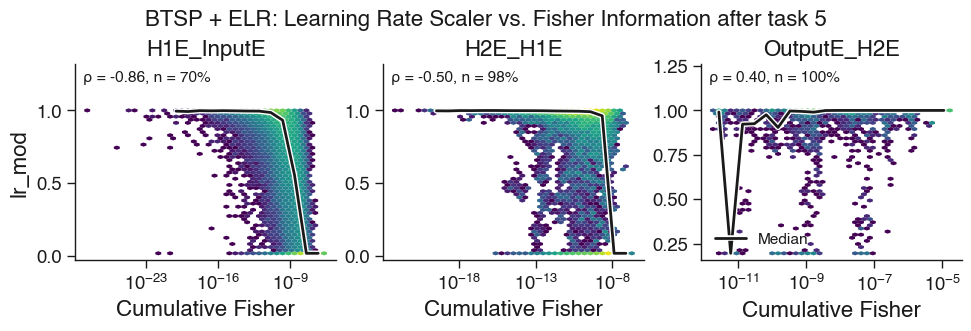

In [13]:
model, seed = 'BTSP_CL_5_tasks_ELR_A', None  # None: first seed
phase = None  # None: after the last task
projections = ['H1E_InputE', 'H2E_H1E', 'OutputE_H2E']  # None: every plastic projection with lr_mod and a nonzero Fisher
fisher_key = 'cumulative_fisher'  # cumulative_fisher (all tasks learned so far) or fisher (task just learned)
silent_weight_bound = -1e-8  # weights with |W| below this after the task are left out
log_scale = 'fisher'  # True: log-log axes, Spearman ρ; 'fisher': log Fisher axis only (semi-log), Spearman ρ; False: linear axes, Pearson r

plot_lr_mod_vs_fisher(model, seed, projections, phase=phase, fisher_key=fisher_key,
                      silent_weight_bound=silent_weight_bound, log_scale=log_scale)

### Fisher distribution after each task
Histogram of the Fisher of one projection's weights (`projection`) after each of the selected tasks (`tasks`, numbered from 1; `None`: all), on a log x axis. One row per model (`hist_models`), one column per task. Bins and axes are shared across the tasks of a model, but not across models, and start at the `lower_percentile` of the nonzero Fisher; smaller values are counted in the first bin. With `smooth` (default 0.2) the histogram is smoothed with a Gaussian kernel of that s.d. in decades; `smooth=None` plots the plain histogram. The y axis is the fraction of the projection's non-silent weights in each of the `num_bins` bins, so weights with F = 0 (which a log axis cannot show) are missing from each curve; their % is printed in the panel. Silent weights have |W| < `silent_weight_bound` after the task. Fisher scales differ between models, so compare shapes, not positions, across rows.

In [14]:
def log_histogram(F, total, edges, smooth=None):
    """
    Histogram of the nonzero values of F on log-spaced bins, as the fraction of total weights in each bin (values
    below the first bin are counted in it).
    :param edges: array; log-spaced bin edges
    :param smooth: float; s.d. (in decades) of a Gaussian kernel applied to the fractions; None or 0: no smoothing
    :return: tuple of arrays: x (bin edges, for ax.stairs; or bin centers, for ax.plot, if smoothed); fraction of
        weights per bin
    """
    counts, _ = np.histogram(np.maximum(F[F > 0], edges[0]), bins=edges)
    fraction = counts / max(total, 1)
    if smooth:
        log_edges = np.log10(edges)
        bin_width = log_edges[1] - log_edges[0]
        return 10 ** ((log_edges[:-1] + log_edges[1:]) / 2), gaussian_filter1d(fraction, smooth / bin_width,
                                                                                mode='constant')
    return edges, fraction


def plot_fisher_histograms(model_keys, projection, seed=None, tasks=None, fisher_key='cumulative_fisher',
                           silent_weight_bound=1e-8, num_bins=60, lower_percentile=0.1, smooth=0.2, name=None):
    """
    Distribution of the Fisher of one projection's weights after the selected tasks; rows: models, columns: tasks,
    saved as <name>.svg.
    :param model_keys: str or list of str; keys of models, one row each
    :param projection: str; <post>_<pre>, e.g. 'H1E_InputE'
    :param seed: str; None: first seed of each model
    :param tasks: list of int; tasks (numbered from 1) after which to plot the Fisher; None: all
    :param fisher_key: 'cumulative_fisher' (tasks learned so far), 'fisher' (task just learned) or 'rule_importance'
        (EWC/SI-type rules; none after the last task)
    :param silent_weight_bound: float; weights with |W| below this after the task are left out
    :param num_bins: int; log-spaced bins over the nonzero range of each model, shared across tasks
    :param lower_percentile: float; the bins start at this percentile of the nonzero Fisher (pooled over tasks), so a
        few tiny values don't stretch the axis; smaller values are counted in the first bin
    :param smooth: float; s.d. (in decades) of the Gaussian kernel that smooths the histogram; None or 0: plain
        histogram
    :param name: str; None: <model>_<projection>_<fisher_key>_histograms_tasks<...>_seed<seed> for one model,
        <projection>_<fisher_key>_histograms_tasks<...> for several
    """
    model_keys = [model_keys] if isinstance(model_keys, str) else list(model_keys)
    tasks = list(range(1, num_tasks + 1)) if tasks is None else sorted(tasks)
    fig, axes = plt.subplots(len(model_keys), len(tasks), figsize=(3.0 * len(tasks) + 0.6, 2.6 * len(model_keys)),
                             sharex='row', sharey='row', squeeze=False, layout='constrained')
    for row, model in zip(axes, model_keys):
        model_seed = fisher_seeds(model)[0] if seed is None else seed
        fi = load_fisher(model, model_seed)
        F_by_task = {}
        # rule_importance is set at the task switch, so there is none after the last task
        for task in tasks:
            phase_data = fi[f'phase{task - 1}']
            if fisher_key in phase_data and projection in phase_data[fisher_key]:
                active = np.abs(phase_data['weight'][projection].ravel()) >= silent_weight_bound
                F_by_task[task] = phase_data[fisher_key][projection].ravel()[active]
        nonzero = np.concatenate([F[F > 0] for F in F_by_task.values()] + [np.empty(0)])
        if nonzero.size:
            edges = np.logspace(np.log10(np.percentile(nonzero, lower_percentile)), np.log10(nonzero.max()),
                                num_bins + 1)
        for ax, task in zip(row, tasks):
            if task not in F_by_task:
                ax.set_axis_off()
                continue
            F = F_by_task[task]
            if nonzero.size:
                x, fraction = log_histogram(F, F.size, edges, smooth)
                if smooth:
                    ax.plot(x, fraction, color=models[model]['color'], linewidth=2.0)
                else:
                    ax.stairs(fraction, x, color=models[model]['color'], linewidth=2.0)
                ax.set_xscale('log')
            ax.text(0.03, 0.97, f'F = 0: {100 * np.mean(F == 0) if F.size else np.nan:.0f}%', transform=ax.transAxes,
                    ha='left', va='top', fontsize='x-small', in_layout=False)
            style_axes(ax)
        # after every task is drawn, so the shared y axis fits all of them
        row[0].set_ylim(bottom=0)
        row[0].set_ylabel(f'{models[model]["label"]}\nFraction of weights')
        x_label = importance_label(fi, fisher_key)
        del fi
    for ax in axes[-1]:
        ax.set_xlabel(x_label)
    for ax, task in zip(axes[0], tasks):
        ax.set_title(f'After task {task}')
    title = f'{projection}: ' + ('Rule Importance' if fisher_key == 'rule_importance' else 'Fisher Information')
    task_label = ''.join(map(str, tasks))
    if len(model_keys) == 1:
        fig.suptitle(f'{models[model_keys[0]]["label"]}, {title} (seed {model_seed})')
        name = (f'{model_keys[0]}_{projection}_{fisher_key}_histograms_tasks{task_label}_seed{model_seed}'
                if name is None else name)
    else:
        fig.suptitle(title)
        name = f'{projection}_{fisher_key}_histograms_tasks{task_label}' if name is None else name
    save_fig(fig, name)
    plt.show()

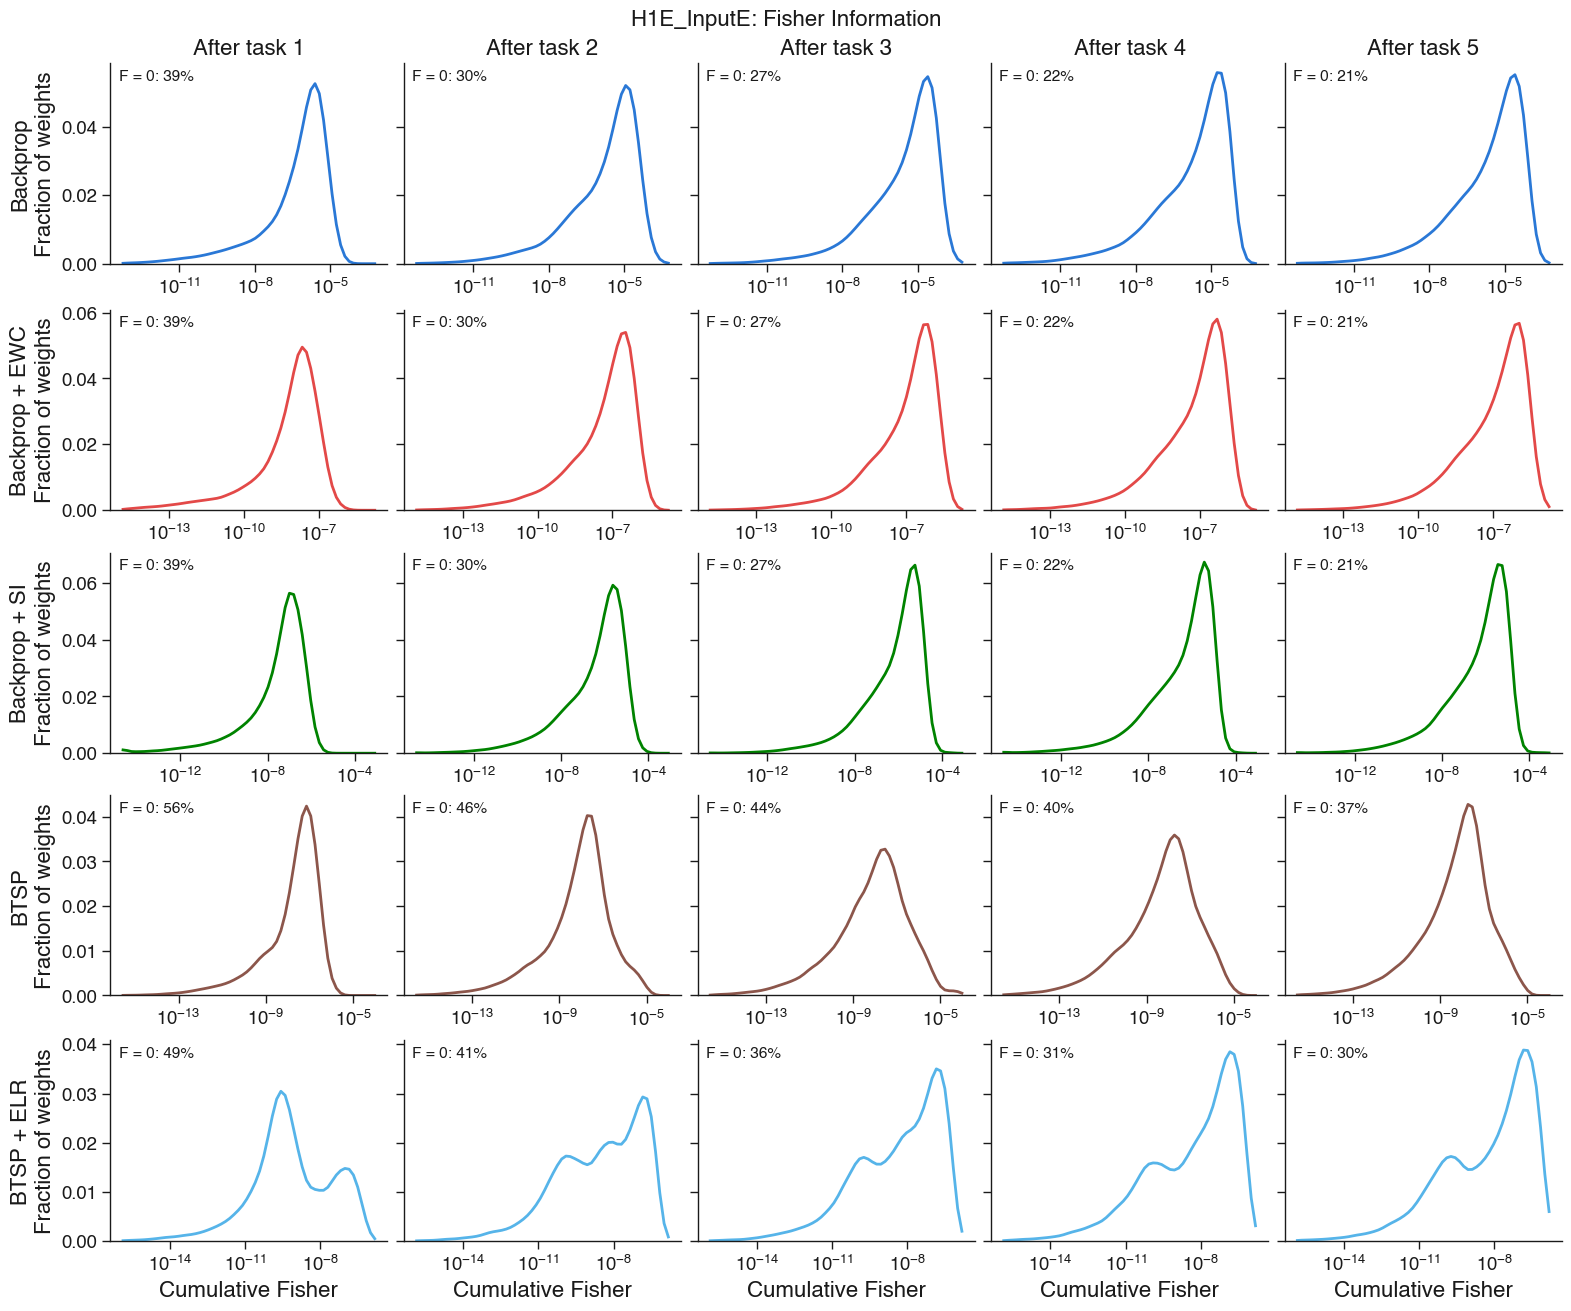

In [15]:
hist_models = ['van_bp_CL_5_tasks_G', 'van_bp_CL_5_tasks_EWC', 'van_bp_CL_5_tasks_SI', 'BTSP_CL_5_tasks_6L', 'BTSP_CL_5_tasks_ELR_A']  # one row each (keys of `models`)
projection = 'H1E_InputE'  # <post>_<pre>
seed = None  # None: first seed of each model
tasks = None  # tasks (numbered from 1) after which to plot the Fisher, one column each; None: all
fisher_key = 'cumulative_fisher'  # cumulative_fisher (all tasks learned so far), fisher (task just learned) or rule_importance (EWC/SI-type rules)
silent_weight_bound = -1e-8  # weights with |W| below this after the task are left out
smooth = 0.2  # s.d. (decades) of the Gaussian smoothing; None or 0: plain histogram
name = None  # saved as <name>.svg; None: named after the model(s), projection, fisher_key and tasks

plot_fisher_histograms(hist_models, projection, seed, tasks=tasks, fisher_key=fisher_key,
                       silent_weight_bound=silent_weight_bound, smooth=smooth, name=name)

### Fisher distribution and learning rate of one projection
One projection (`projection`), in one row of panels sharing the Fisher axis (log scale). First panels: the Fisher histogram of each model in `hist_models` (fraction of weights in each of `num_bins` log-spaced bins, smoothed with `smooth` as above), with one line per task in `tasks` (light: task 1, dark: the last task). Weights with F = 0 can't be shown on a log axis and are missing from each curve. Last panel: for `lr_model` after `lr_task`, the learning rate in effect, η_W = the rule's base `learning_rate` × `lr_mod` (as applied in `BTSP_ELR_1.step` and the SGD-style backprop LR rules; for rules that scale the gradient before an adaptive optimizer it is nominal), against the Fisher per weight (`effective_lr=False`: `lr_mod` itself). The base learning rate is read from the model's phase-0 pickle in `pickle_dir`, so it must be present locally. Color: number of weights (log scale). The line is the median learning rate in each of `num_median_bins` bins of equal width in log Fisher (bins with fewer than `min_bin_count` weights skipped); ρ is the Spearman correlation, on the weights with F > 0. Weights pinned at |W| ≈ 0 (e.g. at a Dale's-law bound) are included by default; set `silent_weight_bound` (e.g. 1e-8) to leave them out.

In [16]:
pickle_dir = '../data'  # holds <network_name>/<network seed>/<network_name>_phase<i>_<seed>_<model key>.pkl
_rule_learning_rates = {}


def rule_learning_rates(model, seed):
    """
    Base learning rate of every projection's learning rule, read from the model's phase-0 pickle (it doesn't change
    during training; only lr_mod does). Cached per model and seed.
    :return: dict {projection: float}
    """
    if (model, seed) not in _rule_learning_rates:
        paths = glob.glob(f'{pickle_dir}/*/*/*_phase0_{seed}_{model}.pkl')
        if len(paths) != 1:
            raise FileNotFoundError(f'expected one phase-0 pickle of {model} seed {seed} in {pickle_dir}, found {paths}')
        network = ut.load_network(paths[0], disp=False)
        _rule_learning_rates[(model, seed)] = {projection.name: float(projection.learning_rule.learning_rate)
                                               for layer in network for population in layer
                                               for projection in population}
    return _rule_learning_rates[(model, seed)]


TASK_COLORS = ['#86b6ef', '#5598e7', '#2a78d6', '#1c5cab', '#104281']  # ordinal blue ramp (validated), task 1 to 5


def plot_fisher_histograms_and_lr(hist_models, lr_model, projection, seed=None, tasks=None, lr_task=None,
                                  fisher_key='cumulative_fisher', silent_weight_bound=0, log_scale='fisher', smooth=0.2,
                                  num_bins=60, lower_percentile=0.1, num_median_bins=20, min_bin_count=20,
                                  effective_lr=True, text_y=None, title=None, name=None):
    """
    One row of panels sharing the Fisher axis: a Fisher histogram of one projection for each of hist_models (one line
    per task), then the learning rate (or lr_mod) against the Fisher of lr_model after lr_task. Saved as <name>.svg.
    :param hist_models: list of str; keys of models, one histogram panel each
    :param lr_model: str; key of a model with lr_mod (e.g. BTSP + ELR)
    :param projection: str; <post>_<pre>, e.g. 'H1E_InputE'
    :param seed: str; None: first seed of each model
    :param tasks: list of int; tasks (numbered from 1) overlaid in each histogram; None: the first and last
    :param lr_task: int; task after which the learning rate is plotted; None: the last of tasks
    :param fisher_key: 'cumulative_fisher' (tasks learned so far) or 'fisher' (task just learned)
    :param silent_weight_bound: float; weights with |W| below this after the task are left out (0: none)
    :param log_scale: True, 'fisher' or False; axes of the learning rate panel, as in plot_lr_mod_vs_fisher
    :param smooth: float; s.d. (in decades) of the Gaussian smoothing of the histograms; None or 0: plain histograms
    :param num_bins: int; log-spaced histogram bins, shared across panels
    :param lower_percentile: float; the bins (and the Fisher axis) start at this percentile of the nonzero Fisher
        (pooled over models and tasks); smaller values are counted in the first bin
    :param num_median_bins: int; Fisher bins for the median line
    :param min_bin_count: int; median bins with fewer weights are left out
    :param effective_lr: if True, plot the learning rate in effect, learning_rate * lr_mod (the rule's base learning
        rate from the phase-0 pickle); if False, lr_mod
    :param text_y: float; y (data units) just above which the ρ text sits; None: the largest value plotted
    :param title: str; figure title; None: <projection>: Fisher Information and Learning Rate; '': no title
    :param name: str; None: <projection>_fisher_histograms_and_<lr | lr_mod>_tasks<...>
    """
    tasks = [1, num_tasks] if tasks is None else sorted(tasks)
    lr_task = tasks[-1] if lr_task is None else lr_task

    def kept_fisher(fi, task):
        F = fi[f'phase{task - 1}'][fisher_key][projection].ravel()
        W = fi[f'phase{task - 1}']['weight'][projection].ravel()
        return F[np.abs(W) >= silent_weight_bound] if silent_weight_bound else F

    # Fisher of every histogram model and task
    hist_F = {}
    for model in hist_models:
        fi = load_fisher(model, fisher_seeds(model)[0] if seed is None else seed)
        hist_F[model] = {task: kept_fisher(fi, task) for task in tasks}
    # learning rate of lr_model
    lr_seed = fisher_seeds(lr_model)[0] if seed is None else seed
    fi = load_fisher(lr_model, lr_seed)
    if projection not in fi[f'phase{lr_task - 1}'].get('lr_mod', {}):
        raise ValueError(f'{lr_model} has no lr_mod for {projection} after task {lr_task}')
    F = fi[f'phase{lr_task - 1}'][fisher_key][projection].ravel()
    lr_mod, silent = weight_quantity(fi, projection, lr_task - 1, 'lr_mod', 0, silent_weight_bound)
    base_lr = rule_learning_rates(lr_model, lr_seed)[projection] if effective_lr else 1.
    lr, silent = base_lr * lr_mod.ravel(), silent.ravel()

    nonzero = np.concatenate([F_task[F_task > 0] for by_task in hist_F.values() for F_task in by_task.values()] +
                             [F[~silent & (F > 0)]])
    # half a decade past the largest value, so the smoothed histograms fall off inside the axes
    edges = np.logspace(np.log10(np.percentile(nonzero, lower_percentile)), np.log10(nonzero.max()) + 0.5,
                        num_bins + 1)
    colors = phase_colors_for(tasks)

    fig, axes = plt.subplots(1, len(hist_models) + 1, figsize=(3.4 * (len(hist_models) + 1), 3.2), sharex=True,
                             layout='constrained')
    for ax in axes[1:-1]:
        ax.sharey(axes[0])
    for ax, model in zip(axes, hist_models):
        for task in tasks:
            F_task = hist_F[model][task]
            x, fraction = log_histogram(F_task, F_task.size, edges, smooth)
            if smooth:
                ax.plot(x, fraction, color=colors[task], linewidth=2.0, label=f'After task {task}')
            else:
                ax.stairs(fraction, x, color=colors[task], linewidth=2.0, label=f'After task {task}')
        ax.set_title(models[model]['label'])
        style_axes(ax)
    axes[0].set_xscale('log')
    axes[0].set_ylim(bottom=0)
    axes[0].set_ylabel('Fraction of weights')
    axes[0].legend(frameon=False, loc='upper left', fontsize='x-small')

    lr_ax = axes[-1]
    xscale, yscale = axis_scales(log_scale)
    keep = ~silent & ((F > 0) if xscale == 'log' else True) & ((lr > 0) if yscale == 'log' else True)
    if text_y is None:
        text_y = lr[~silent].max()
    if keep.any():
        lr_ax.hexbin(F[keep], lr[keep], xscale=xscale, yscale=yscale, bins='log', gridsize=40, mincnt=1,
                     cmap='viridis', linewidths=0)
        centers, medians = binned_median(F[keep], lr[keep], num_median_bins, min_bin_count, xscale == 'log')
        # white halo keeps the line visible over dark and light hexbins
        lr_ax.plot(centers, medians, color=INK, linewidth=2.0, solid_capstyle='round',
                   path_effects=[patheffects.withStroke(linewidth=4.0, foreground='white')])
    annotate_correlation(lr_ax, F[keep], lr[keep], F.size, log_scale=log_scale, show_counts=False, text_y=text_y)
    bottom, top = lr_ax.get_ylim()
    # room above text_y for the annotation
    lr_ax.set_ylim(bottom, max(top, text_y * 2.5 if yscale == 'log' else text_y + 0.15 * (text_y - bottom)))
    lr_ax.set_ylabel(r'$\eta_W$' if effective_lr else weight_change_label(False, 'lr_mod'))
    lr_ax.set_title(f'{models[lr_model]["label"]}, after task {lr_task}')
    style_axes(lr_ax)
    for ax in axes:
        ax.set_xlabel('Fisher Information')
    axes[0].set_xlim(edges[0], edges[-1])

    if title is None:
        title = f'{projection}: Fisher Information and {"Learning Rate" if effective_lr else "Learning Rate Scaler"}'
    if title:
        fig.suptitle(title)
    task_label = ''.join(map(str, tasks))
    save_fig(fig, f'{projection}_fisher_histograms_and_{"lr" if effective_lr else "lr_mod"}_tasks{task_label}'
                  f'{scale_file_label(log_scale)}' if name is None else name)
    plt.show()


def phase_colors_for(tasks):
    """
    :return: dict {task: color}; tasks keep their color from TASK_COLORS (light: task 1, dark: the last task) whichever
        are shown
    """
    ramp = [TASK_COLORS[i] for i in np.round(np.linspace(0, len(TASK_COLORS) - 1, num_tasks)).astype(int)]
    return {task: ramp[task - 1] for task in tasks}

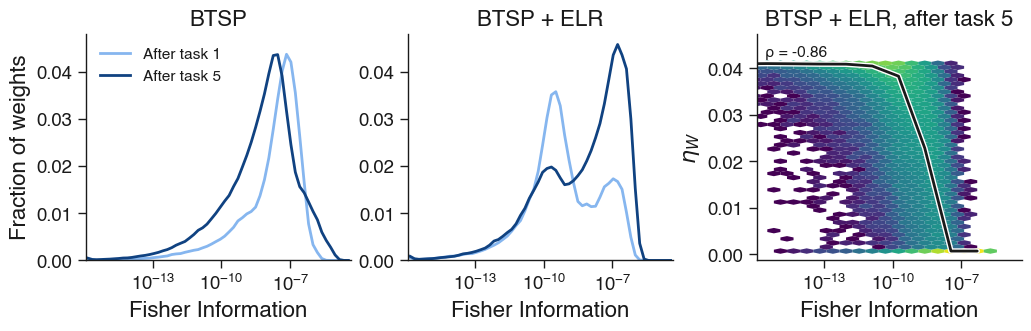

In [17]:
hist_models = ['BTSP_CL_5_tasks_6L', 'BTSP_CL_5_tasks_ELR_A']  # one histogram panel each
lr_model = 'BTSP_CL_5_tasks_ELR_A'  # model whose learning rate is plotted in the last panel (needs lr_mod)
seed = None  # None: first seed of each model
projection = 'H1E_InputE'  # <post>_<pre>
tasks = [1, 5]  # tasks (numbered from 1) overlaid in each histogram
lr_task = 5  # task after which the learning rate is plotted; None: the last of tasks
fisher_key = 'cumulative_fisher'  # cumulative_fisher (all tasks learned so far) or fisher (task just learned)
silent_weight_bound = 0  # weights with |W| below this after the task are left out; 0: keep all (e.g. 1e-8 drops weights pinned at 0)
log_scale = 'fisher'  # True: log-log axes, Spearman ρ; 'fisher': log Fisher axis only (semi-log), Spearman ρ; False: linear axes, Pearson r
smooth = 0.1  # s.d. (decades) of the Gaussian smoothing of the histograms; None or 0: plain histograms
effective_lr = True  # True: learning rate in effect (learning_rate * lr_mod); False: lr_mod
text_y = None  # y (data units) just above which the ρ text sits; None: the largest value plotted
title = ''  # figure title; None: projection; '': no title
name = 'BTSP_ELR_fisher_v_learning_rate'  # saved as <name>.svg; None: named after the projection and tasks

plot_fisher_histograms_and_lr(hist_models, lr_model, projection, seed, tasks=tasks, lr_task=lr_task,
                              fisher_key=fisher_key, silent_weight_bound=silent_weight_bound, log_scale=log_scale,
                              smooth=smooth, effective_lr=effective_lr, text_y=text_y, title=title, name=name)

### Weight change vs rule importance
|ΔW| during task *i*+1 against the importance the rule itself uses to protect tasks 1..*i* (`fisher_key='rule_importance'`): ΣF for EWC and EWC_LR, ω for SI and SI_LR. EWC and SI penalize changes in proportion to it, while EWC_LR and SI_LR scale the learning rate down by `lr_mod_func(importance)`, so high-importance weights should change less. With `quantity='lr_mod'` the y axis is the `lr_mod` of EWC_LR and SI_LR instead, which is a function of the importance and so checks the threshold settings (how many weights are slowed or frozen).

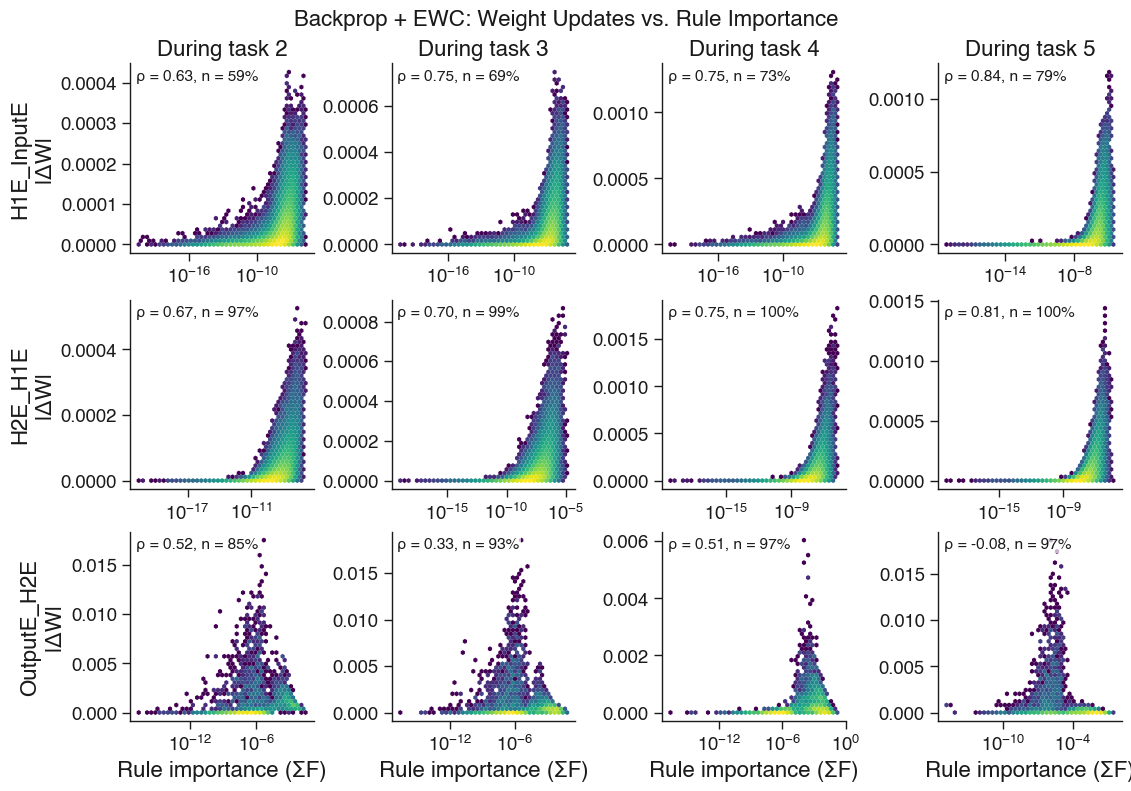

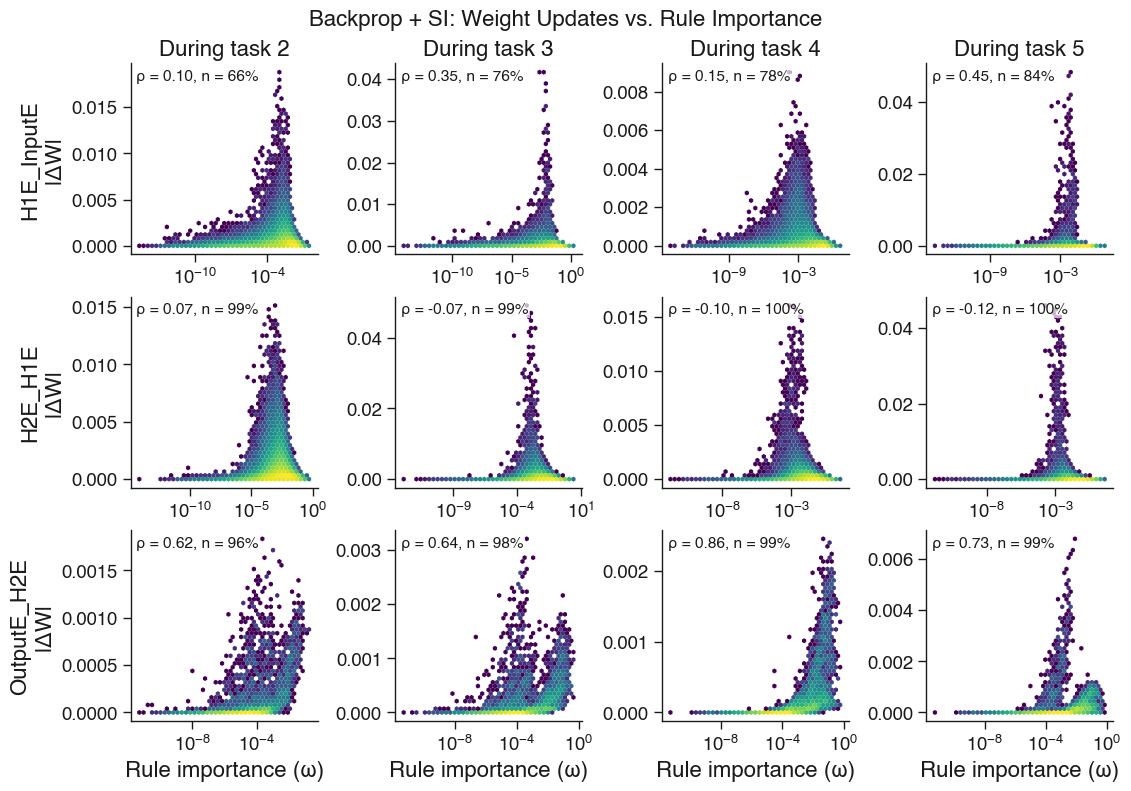

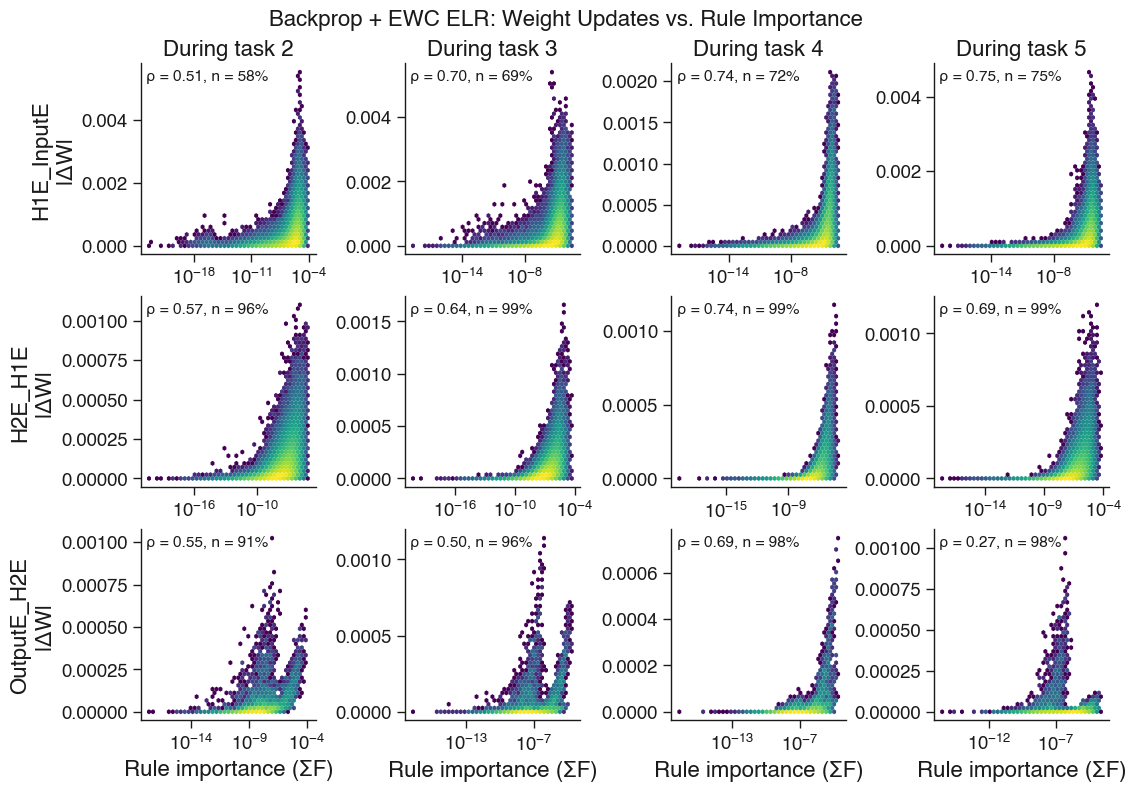

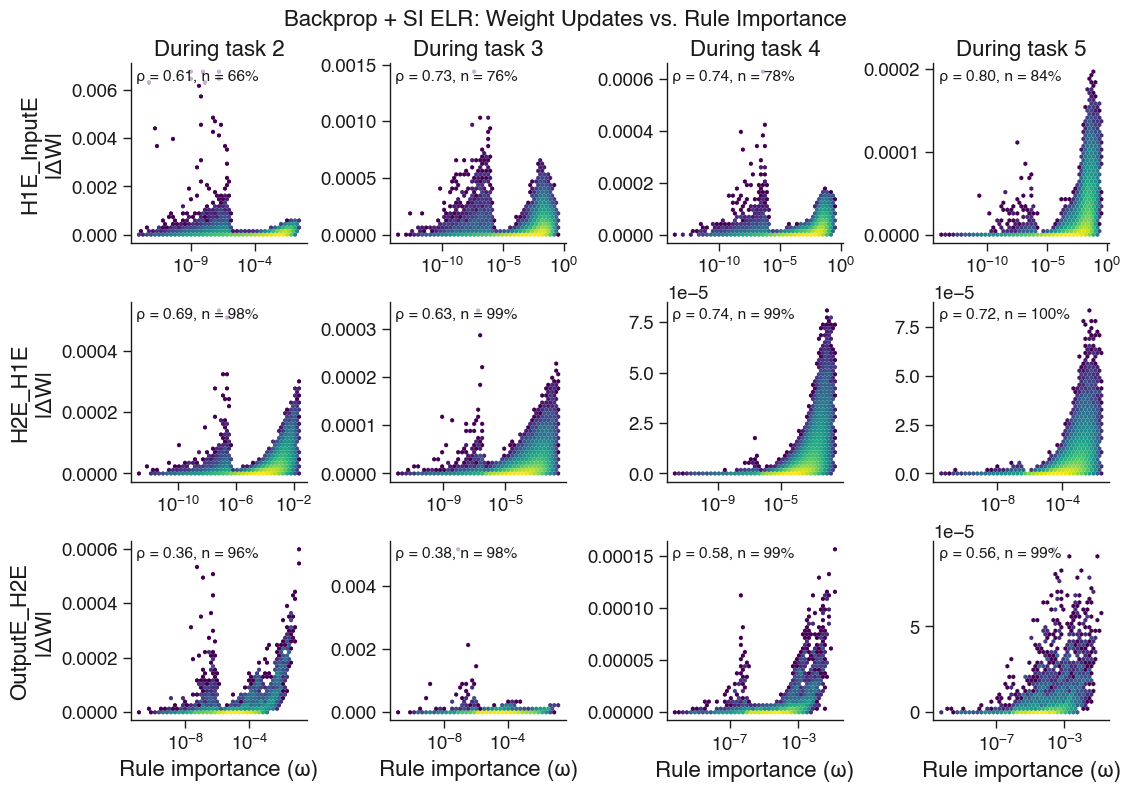

In [18]:
importance_models = ['van_bp_CL_5_tasks_EWC', 'van_bp_CL_5_tasks_SI', 'van_bp_CL_5_tasks_EWC_LR', 'van_bp_CL_5_tasks_SI_LR']
seed = None  # None: first seed
quantity = 'dW'  # 'dW' or 'lr_mod' (EWC_LR and SI_LR only)
projections = None  # None: every projection with a nonzero rule importance
dw_lower_bound = 1e-8  # |ΔW| below this counts as no change (float32 resolves about |W| * 6e-8)
silent_weight_bound = 1e-8  # weights with |W| below this before and after the task are left out
relative = False  # True: plot |ΔW| / |W before the task| instead of |ΔW|
log_scale = 'fisher'  # True: log-log axes, Spearman ρ; 'fisher': log Fisher axis only (semi-log), Spearman ρ; False: linear axes, Pearson r

for model in importance_models:
    if quantity == 'lr_mod' and not model.endswith('_LR'):
        continue
    plot_dw_vs_fisher(model, seed, projections, fisher_key='rule_importance', dw_lower_bound=dw_lower_bound,
                      silent_weight_bound=silent_weight_bound, relative=relative, quantity=quantity,
                      log_scale=log_scale)

## Population activity
`<model_key>_activity.h5` holds the class-averaged test activity of every population after each phase: `<seed>/phase<i>/average_pop_activity_dict/<pop>` (classes, units) and `<seed>/phase<i>/unit_labels_dict/<pop>`. Add representation analyses (selectivity, sparsity, similarity across phases) below.

In [11]:
def activity_path(model):
    return f'{metrics_dir}/{model}_activity.h5'


def load_activity(model, seed, phase):
    """
    :return: dict {'average_pop_activity_dict': {pop: (classes, units)}, 'unit_labels_dict': {pop: (units,)}}
    """
    return ut.hdf5_to_dict(activity_path(model), variable_name=f'{seed}/phase{phase}')


def activity_seeds(model):
    with h5py.File(activity_path(model), 'r') as f:
        return sorted(f.keys())

In [12]:
models = {
    # one unique color per model (validated for adjacent-pair color-vision-deficiency separation); keep in sync across cells
    'van_bp_CL_5_tasks_G':        {'label': 'Backprop',                    'color': '#2a78d6'},  # blue
    'van_bp_CL_5_tasks_EWC':      {'label': 'Backprop + EWC',              'color': '#e34948'},  # red
    'van_bp_CL_5_tasks_EWC_LR':   {'label': 'Backprop + EWC ELR',          'color': '#eda100'},  # yellow
    'van_bp_CL_5_tasks_SI':       {'label': 'Backprop + SI',               'color': '#008300'},  # green
    'van_bp_CL_5_tasks_SI_LR':    {'label': 'Backprop + SI ELR',           'color': '#e87ba4'},  # pink
    'van_bp_CL_5_tasks_SI_HG_v1': {'label': 'Backprop + SI HG',            'color': '#00807f'},  # teal
    'bpDale_CL_5_tasks_G':        {'label': "Backprop (Dale's Law)",       'color': '#4a3aa7'},  # violet
    'bpDale_CL_5_tasks_SI':       {'label': "Backprop (Dale's Law) + SI",  'color': '#1baf7a'},  # aqua
    'bpDale_CL_5_tasks_EWC':      {'label': "Backprop (Dale's Law) + EWC", 'color': '#b5179e'},  # plum
    'BP_like_CL_5_tasks_5J':      {'label': 'DTP',                         'color': '#1a1a1a'},  # black
    'dtp_CL_5_tasks_SI':          {'label': 'DTP + SI',                    'color': '#eb6834'},  # orange
    'BTSP_CL_5_tasks_6L':         {'label': 'BTSP',                        'color': '#8c564b'},  # brown
    'BTSP_CL_5_tasks_ELR_A':      {'label': 'BTSP + ELR',                  'color': '#56b4e9'},  # sky blue
    'BTSP_SI_CL_5_tasks':         {'label': 'BTSP + SI',                   'color': '#9a9a00'},  # olive
    'BTSP_BP_CL_5_tasks':         {'label': 'BTSP (BP plateaus)',          'color': '#9467bd'},  # purple
}

model, seed = 'BP_like_CL_5_tasks_5J', None
populations = {'OutputE': 'Output', 'H2E': 'H2E', 'H1E': 'H1E'}  # population: y label, top to bottom


def sort_by_preferred_class(activity):
    """
    Order units by the class they respond to most strongly, then by peak activity (descending). Silent units go last.
    :param activity: array (classes, units)
    :return: array (classes, units)
    """
    peak = activity.max(0)
    preferred = np.where(peak > 0, activity.argmax(0), activity.shape[0])
    return activity[:, np.lexsort((-peak, preferred))]


def plot_sorted_activity(ax, activity, vmax):
    """
    Square heatmap of class-averaged activity, classes on x and units (sorted by preferred class) on y.
    """
    ax.imshow(sort_by_preferred_class(activity).T, aspect='auto', vmin=0, vmax=vmax, cmap='magma',
              interpolation='none')
    ax.set_box_aspect(1)
    ax.set_xticks(range(activity.shape[0]))
    ax.set_yticks([-0.5, activity.shape[1] - 0.5], [0, activity.shape[1]])  # on the image edges


def activity_grid(num_cols, width, sharey=False):
    """
    :param sharey: if True, y ticks are shown on the first column only
    :return: fig, axes (populations, num_cols) with class labels on the bottom row only
    """
    fig, axes = plt.subplots(len(populations), num_cols, figsize=(width, 2.0 * len(populations)), squeeze=False,
                             sharex=True, sharey='row' if sharey else False, layout='constrained')
    for ax in axes[-1]:
        ax.set_xlabel('Class')
    for ax, label in zip(axes[:, 0], populations.values()):
        ax.set_ylabel(f'{label} unit')
    return fig, axes


seed = activity_seeds(model)[0] if seed is None else seed
activities = {population: [load_activity(model, seed, phase)['average_pop_activity_dict'][population]
                           for phase in range(num_tasks)]
              for population in populations}


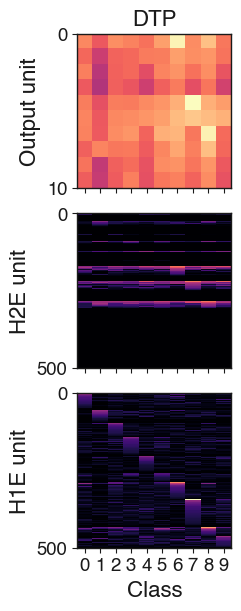

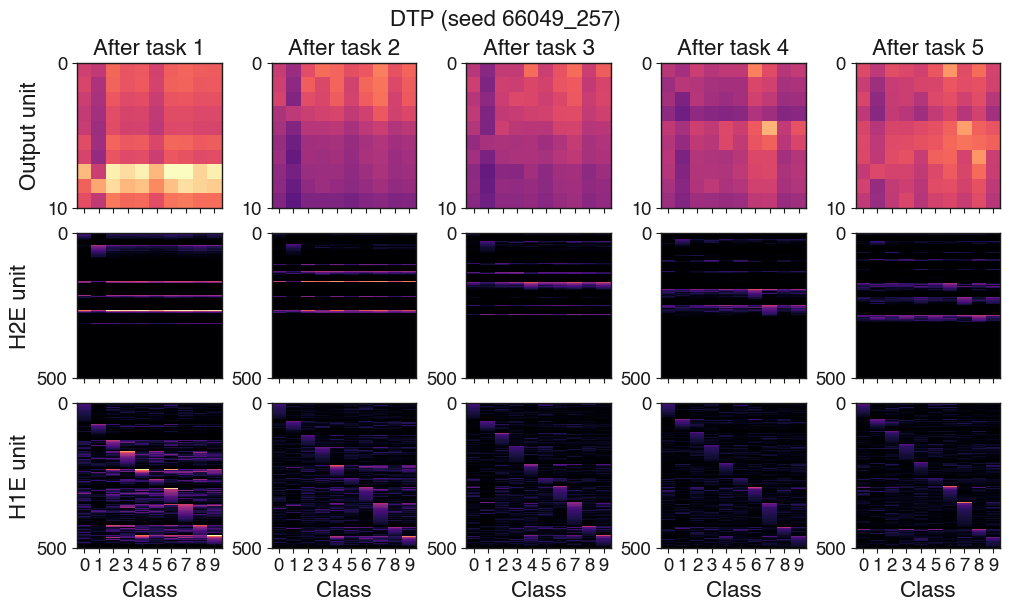

In [13]:
fig, axes = activity_grid(1, 2.4)
for ax, population in zip(axes[:, 0], populations):
    plot_sorted_activity(ax, activities[population][-1], activities[population][-1].max())
axes[0, 0].set_title(f'{models[model]["label"]}')
save_fig(fig, f'{model}_activity_final_seed{seed}')
plt.show()

fig, axes = activity_grid(num_tasks, 2.0 * num_tasks)
for row, population in zip(axes, populations):
    vmax = max(activity.max() for activity in activities[population])
    for ax, activity in zip(row, activities[population]):
        plot_sorted_activity(ax, activity, vmax)
for phase, ax in enumerate(axes[0]):
    ax.set_title(f'After task {phase + 1}')
fig.suptitle(f'{models[model]["label"]} (seed {seed})')
save_fig(fig, f'{model}_activity_phases_seed{seed}')
plt.show()


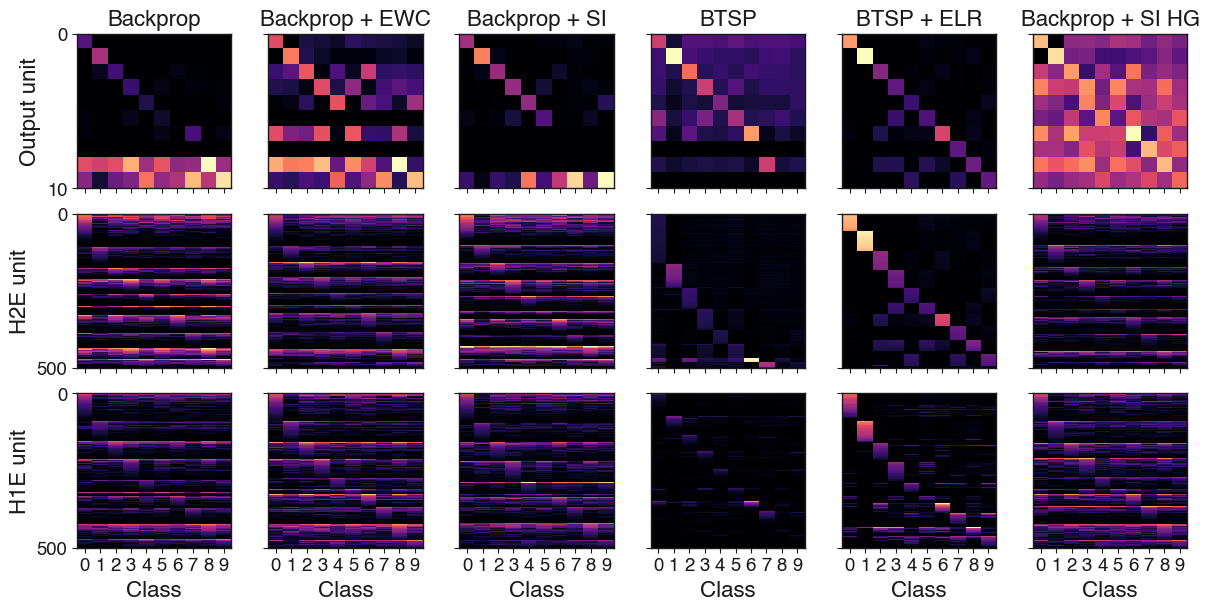

In [14]:
# final activity of several models side by side, each panel scaled to its own max
compare_models = ['van_bp_CL_5_tasks_G', 'van_bp_CL_5_tasks_EWC', 'van_bp_CL_5_tasks_SI', 'BTSP_CL_5_tasks_6L', 'BTSP_CL_5_tasks_ELR_A', 'van_bp_CL_5_tasks_SI_HG_v1']
compare_seed = None  # None: first seed of each model
compare_name = 'activity_final_models'  # saved as <compare_name>.svg

final_activities = {}
for m in compare_models:
    m_seed = activity_seeds(m)[0] if compare_seed is None else compare_seed
    pop_activity = load_activity(m, m_seed, num_tasks - 1)['average_pop_activity_dict']
    final_activities[m] = {population: pop_activity[population] for population in populations}

fig, axes = activity_grid(len(compare_models), 2.0 * len(compare_models), sharey=True)
for col, m in zip(axes.T, compare_models):
    for ax, population in zip(col, populations):
        plot_sorted_activity(ax, final_activities[m][population], final_activities[m][population].max())
    col[0].set_title(models[m]['label'])
save_fig(fig, compare_name)
plt.show()


### Weight change vs contribution utility
Contribution utility (Dohare et al. 2024, Nature) of every unit after task *i*: mean |activity| on training samples of that task × Σ |outgoing weights| over somatic projections (`<seed>/phase<i>/contribution_utility/<pop>`). Each point is one unit: its utility after task *i* against the mean |ΔW| of its weights during task *i*+1, on log–log axes. `side='out'` averages over the outgoing weights that make up the utility; `side='in'` averages over the unit's incoming somatic weights (how much its tuning changes). Column *k*: utility after task *k*−1, ΔW during task *k*. Silent weights (|W| < `silent_weight_bound` before and after the task) are left out of each unit's mean, and changes below `dw_lower_bound` count as 0, as in the Fisher plots. `relative=True` averages the relative change |ΔW| / |W| instead, and `quantity='lr_mod'` the learning rate modulation after each task (over the unit's weights that have one), against the utility at the same phase, one column per task. Units with zero utility, only silent weights, or no change are left out (*n* = % of units shown). `log_scale=False` uses linear axes (keeping zeros). The weights come from `<model_key>_fisher.h5`.

In [23]:
def somatic_projections(model, seed):
    """
    :return: list of str; names (<post>_<pre>) of the projections that count toward the contribution utility
    """
    with h5py.File(activity_path(model), 'r') as f:
        return list(f[f'{seed}/phase0/outgoing_weight'].keys())


def unit_mean_abs_weight_change(fi, projections, population, phase, side, dw_lower_bound, silent_weight_bound,
                                relative=False, quantity='dW'):
    """
    :param side: 'out' (weights from each unit of population) or 'in' (weights onto it)
    :param relative: if True, average the relative change |ΔW| / |W| instead
    :param quantity: 'dW' or 'lr_mod' (averaged over the projections that have one)
    :return: array (units,); mean |ΔW| (or relative change) during the task after phase over each unit's non-silent weights (nan if all
        are silent)
    """
    unit_dW, unit_silent = [], []
    for projection in projections:
        post, pre = projection.split('_')
        if quantity == 'lr_mod' and projection not in fi[f'phase{phase}'].get('lr_mod', {}):
            continue
        if (side == 'out' and pre == population) or (side == 'in' and post == population):
            dW, silent = weight_quantity(fi, projection, phase, quantity, dw_lower_bound, silent_weight_bound,
                                         relative)
            unit_dW.append(dW.T if side == 'out' else dW)
            unit_silent.append(silent.T if side == 'out' else silent)
    if not unit_dW:
        raise ValueError(f'no {side}going projections of {population} with {quantity}')
    dW, active = np.concatenate(unit_dW, axis=1), ~np.concatenate(unit_silent, axis=1)
    with np.errstate(invalid='ignore'):
        return (dW * active).sum(1) / active.sum(1)


def plot_dw_vs_utility(model, seed=None, utility_populations=('H1E', 'H2E'), side='out', dw_lower_bound=1e-8,
                       silent_weight_bound=1e-6, relative=False, quantity='dW', log_scale=True):
    """
    Mean |ΔW| of each unit's weights during task i+1 against its contribution utility after task i; rows: populations,
    columns: task switches. With quantity='lr_mod': mean lr_mod after task i against the utility after task i, one
    column per task.
    :param quantity: 'dW' (weight change) or 'lr_mod' (learning rate modulation after task i)
    :param log_scale: if True, log-log axes and Spearman ρ, leaving out zeros; if False, linear axes and Pearson r
    """
    seed = activity_seeds(model)[0] if seed is None else seed
    fi = load_fisher(model, seed)
    projections = somatic_projections(model, seed)
    phases, titles = plot_phases(quantity)
    fig, axes = plt.subplots(len(utility_populations), len(phases),
                             figsize=(2.8 * len(phases), 2.6 * len(utility_populations)), squeeze=False,
                             layout='constrained')
    for row, population in zip(axes, utility_populations):
        for phase, ax in zip(phases, row):
            utility = load_activity(model, seed, phase)['contribution_utility'][population]
            dW = unit_mean_abs_weight_change(fi, projections, population, phase, side, dw_lower_bound,
                                             silent_weight_bound, relative, quantity)
            keep = (utility > 0) & (dW > 0) if log_scale else np.isfinite(dW)  # nan: only silent weights
            ax.scatter(utility[keep], dW[keep], s=8, alpha=0.5, color=models[model]['color'], linewidths=0)
            if log_scale:
                ax.set_xscale('log')
                ax.set_yscale('log')
            #annotate_correlation(ax, utility[keep], dW[keep], utility.size, log_scale=log_scale)
            style_axes(ax)
        row[0].set_ylabel(f'{population}\nmean {weight_change_label(relative, quantity)} ({side})')
    for title, ax in zip(titles, axes[0]):
        ax.set_title(title)
    for ax in axes[-1]:
        ax.set_xlabel('Contribution utility')
    fig.suptitle(f'{models[model]["label"]}: Weight Update vs Contribution')
    save_fig(fig, f'{model}_{weight_quantity_file_label(relative, quantity)}_{side}_vs_utility'
                  f'{"" if log_scale else "_linear"}_seed{seed}')
    plt.show()

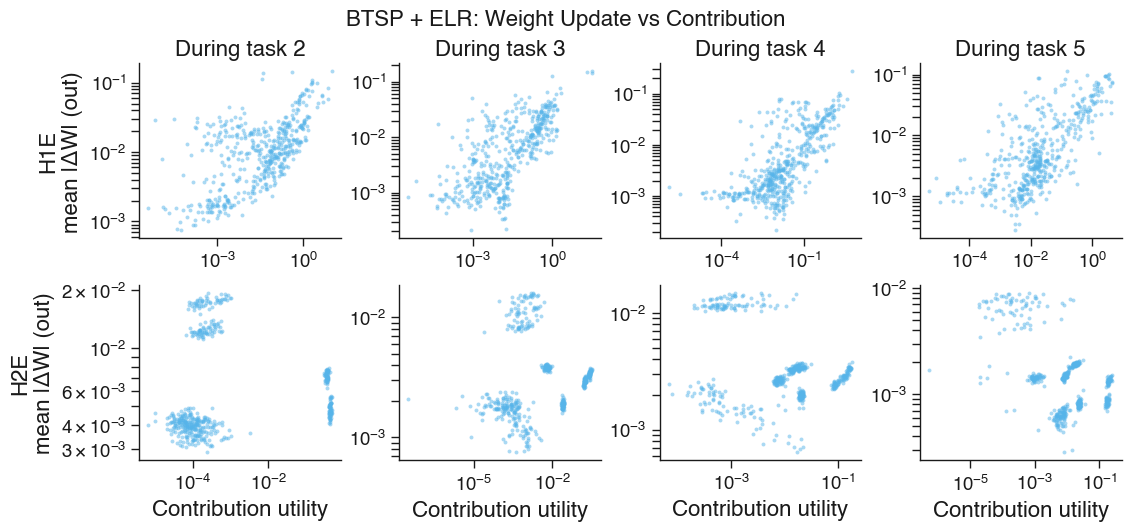

In [24]:
models = {
    # one unique color per model (validated for adjacent-pair color-vision-deficiency separation); keep in sync across cells
    'van_bp_CL_5_tasks_G':        {'label': 'Backprop',                    'color': '#2a78d6'},  # blue
    'van_bp_CL_5_tasks_EWC':      {'label': 'Backprop + EWC',              'color': '#e34948'},  # red
    'van_bp_CL_5_tasks_EWC_LR':   {'label': 'Backprop + EWC ELR',          'color': '#eda100'},  # yellow
    'van_bp_CL_5_tasks_SI':       {'label': 'Backprop + SI',               'color': '#008300'},  # green
    'van_bp_CL_5_tasks_SI_LR':    {'label': 'Backprop + SI ELR',           'color': '#e87ba4'},  # pink
    'van_bp_CL_5_tasks_SI_HG_v1': {'label': 'Backprop + SI HG',            'color': '#00807f'},  # teal
    'bpDale_CL_5_tasks_G':        {'label': "Backprop (Dale's Law)",       'color': '#4a3aa7'},  # violet
    'bpDale_CL_5_tasks_SI':       {'label': "Backprop (Dale's Law) + SI",  'color': '#1baf7a'},  # aqua
    'bpDale_CL_5_tasks_EWC':      {'label': "Backprop (Dale's Law) + EWC", 'color': '#b5179e'},  # plum
    'BP_like_CL_5_tasks_5J':      {'label': 'DTP',                         'color': '#1a1a1a'},  # black
    'dtp_CL_5_tasks_SI':          {'label': 'DTP + SI',                    'color': '#eb6834'},  # orange
    'BTSP_CL_5_tasks_6L':         {'label': 'BTSP',                        'color': '#8c564b'},  # brown
    'BTSP_CL_5_tasks_ELR_A':      {'label': 'BTSP + ELR',                  'color': '#56b4e9'},  # sky blue
    'BTSP_SI_CL_5_tasks':         {'label': 'BTSP + SI',                   'color': '#9a9a00'},  # olive
    'BTSP_BP_CL_5_tasks':         {'label': 'BTSP (BP plateaus)',          'color': '#9467bd'},  # purple
}

model, seed = 'BTSP_CL_5_tasks_ELR_A', None  # None: first seed
dw_lower_bound = 1e-8  # |ΔW| below this counts as no change (float32 resolves about |W| * 6e-8)
silent_weight_bound = 1e-6  # weights with |W| below this before and after the task are left out
relative = False  # True: plot |ΔW| / |W before the task| instead of |ΔW|
quantity = 'dW'  # 'dW' or 'lr_mod' (learning rate modulation of rules that have one, e.g. BTSP + ELR)
log_scale = True  # True: log-log axes, Spearman ρ; False: linear axes, Pearson r

plot_dw_vs_utility(model, seed, utility_populations=('H1E', 'H2E'), side='out', dw_lower_bound=dw_lower_bound,
                    silent_weight_bound=silent_weight_bound, relative=relative, quantity=quantity, log_scale=log_scale)